# **Loading the Files**


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
BASE_PATH = "/content/drive/MyDrive/Projects/Tennis/v1_1/datasets"


In [3]:
import pandas as pd

train = pd.read_parquet(f"{BASE_PATH}/v1_1_train.parquet")
val = pd.read_parquet(f"{BASE_PATH}/v1_1_val.parquet")
test = pd.read_parquet(f"{BASE_PATH}/v1_1_test.parquet")

train_log = pd.read_parquet(f"{BASE_PATH}/v1_1_train_log.parquet")
val_log = pd.read_parquet(f"{BASE_PATH}/v1_1_val_log.parquet")
test_log = pd.read_parquet(f"{BASE_PATH}/v1_1_test_log.parquet")


In [4]:
# V1.1 preflight: check schemas, metadata alignment, and chronological CV groups.
from pathlib import Path
import numpy as np
from sklearn.model_selection import TimeSeriesSplit

PROJECT_DIR = Path(BASE_PATH).parent
match_metadata = pd.read_csv(Path(BASE_PATH) / "matches_v1_1_metadata.csv")
metadata_by_split = {
    split: match_metadata.loc[match_metadata["split"].eq(split)].reset_index(drop=True)
    for split in ("train", "val", "test")
}
for name, normal, logged in (("train", train, train_log),
                             ("val", val, val_log),
                             ("test", test, test_log)):
    if len(normal) != len(logged) or len(normal) != len(metadata_by_split[name]):
        raise ValueError(f"{name}: parquet files and evaluation metadata are misaligned")
    if not normal.columns.equals(logged.columns):
        raise ValueError(f"{name}: regular/log feature schemas differ")
    forbidden = {"playerA_wins", "match_id", "score", "minutes"}
    if forbidden.intersection(normal.columns):
        raise ValueError(f"{name}: outcome or identifier present among model columns")
    if not {"playerA_match_p", "playerB_match_p"}.issubset(normal.columns):
        raise ValueError(f"{name}: missing regression targets")
    if not normal.drop(columns=["playerA_match_p", "playerB_match_p"]).columns.equals(
            train.drop(columns=["playerA_match_p", "playerB_match_p"]).columns):
        raise ValueError(f"{name}: feature ordering differs from train")

train_dates = pd.to_datetime(metadata_by_split["train"]["tourney_date"]).reset_index(drop=True)
if train_dates.isna().any() or not train_dates.is_monotonic_increasing:
    raise ValueError("Training tournament dates must be present and chronologically ordered")

def date_grouped_cv(n_splits=3, dates=None):
    # Expand TimeSeriesSplit on unique dates back to rows: never split a tournament week.
    d = pd.to_datetime(train_dates if dates is None else dates).reset_index(drop=True)
    unique_dates = np.sort(d.unique())
    if len(unique_dates) <= n_splits:
        raise ValueError("Insufficient distinct tournament dates for grouped CV")
    return [(np.flatnonzero(d.isin(unique_dates[tr]).to_numpy()),
             np.flatnonzero(d.isin(unique_dates[va]).to_numpy()))
            for tr, va in TimeSeriesSplit(n_splits=n_splits).split(unique_dates)]

for subdir in ("models/raw_models", "models/stage1_models", "models/stage2_models",
               "models/stage3_models", "models/ensembles", "SHAP", "Permutation"):
    (PROJECT_DIR / subdir).mkdir(parents=True, exist_ok=True)

if not metadata_by_split["test"]["playerA_wins"].isin([0, 1]).all():
    raise ValueError("Missing/invalid playerA_wins in held-out test metadata")
print("V1.1 preflight passed; inputs and metadata are aligned.")


V1.1 preflight passed; inputs and metadata are aligned.


# **Seperating Predictors and Labels**


In [5]:
import gc
target_cols = ['playerA_match_p', 'playerB_match_p']

X_train_log = train_log.drop(columns= target_cols, axis= 1)
y_trainA_log = train_log[target_cols[0]]
y_trainB_log = train_log[target_cols[1]]

X_val_log = val_log.drop(columns= target_cols, axis= 1)
y_valA_log = val_log[target_cols[0]]
y_valB_log = val_log[target_cols[1]]

del train_log
del val_log
gc.collect()


30

In [6]:
import gc
target_cols = ['playerA_match_p', 'playerB_match_p']

X_train = train.drop(columns= target_cols, axis= 1)
y_trainA = train[target_cols[0]]
y_trainB = train[target_cols[1]]

X_val = val.drop(columns= target_cols, axis= 1)
y_valA = val[target_cols[0]]
y_valB = val[target_cols[1]]

del val
del train
gc.collect()


0

In [7]:
import gc
target_cols = ['playerA_match_p', 'playerB_match_p']

test_winner = metadata_by_split["test"]["playerA_wins"].astype(int).reset_index(drop=True)
X_test = test.drop(columns= target_cols, axis = 1)
y_testA = test[target_cols[0]]
y_testB = test[target_cols[1]]

X_test_log = test_log.drop(columns= target_cols, axis= 1)

del test
del test_log
gc.collect()


0

# **Training Models**


## Importing Libraries

In [8]:
!git clone https://github.com/rapidsai/rapidsai-csp-utils.git

Cloning into 'rapidsai-csp-utils'...


remote: Enumerating objects: 719, done.
remote: Counting objects: 100% (235/235), done.
remote: Compressing objects: 100% (89/89), done.
remote: Total 719 (delta 198), reused 152 (delta 146), pack-reused 484 (from 1)
Receiving objects: 100% (719/719), 259.08 KiB | 1.54 MiB/s, done.
Resolving deltas: 100% (382/382), done.


In [9]:
!python rapidsai-csp-utils/colab/pip-install.py

Installing RAPIDS remaining 26.06 libraries
Using Python 3.13.16 environment at: /usr


Resolved 111 packages in 1.25s
Prepared 1 package in 134ms
Installed 1 package in 5ms
 + cugraph-cu13==26.6.0

        ***********************************************************************
        The pip install of RAPIDS is complete.

        Please do not run any further installation from the conda based installation methods, as they may cause issues!

        Please ensure that you're pulling from the git repo to remain updated with the latest working install scripts.

        Troubleshooting:
            - If there is an installation failure, please check back on RAPIDSAI owned templates/notebooks to see how to update your personal files.
            - If an installation failure persists when using the latest script, please make an issue on https://github.com/rapidsai-community/rapidsai-csp-utils
        ***********************************************************************
        


In [10]:
import cuml
print(cuml.__version__)

# Fail early if the installed RAPIDS version cannot use sklearn CV Pipelines.
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import RandomizedSearchCV
from cuml.linear_model import Ridge as cuRidge, ElasticNet as cuElasticNet
import copy

smoke_X = X_train_log.iloc[:48].astype("float32")
smoke_y = y_trainA_log.iloc[:48].astype("float32")
if len(smoke_X) < 20:
    raise ValueError("Not enough rows for the GPU training preflight")
for estimator in (cuRidge(alpha=1.0, output_type="numpy"),
                  cuElasticNet(alpha=0.1, l1_ratio=0.5)):
    smoke_pipe = Pipeline([("scaler", StandardScaler()), ("model", estimator)])
    smoke_cv = RandomizedSearchCV(smoke_pipe, {"model__alpha": [0.5]},
                                  n_iter=1, cv=2, error_score="raise")
    smoke_cv.fit(smoke_X, smoke_y)
    if not np.isfinite(smoke_cv.predict(smoke_X.iloc[:3])).all():
        raise ValueError("GPU Pipeline returned non-finite predictions")
    converted = smoke_cv.best_estimator_.named_steps["model"].as_sklearn()
    inference_pipe = Pipeline([
        ("scaler", copy.deepcopy(smoke_cv.best_estimator_.named_steps["scaler"])),
        ("model", converted),
    ])
    if not np.isfinite(inference_pipe.predict(smoke_X.iloc[:3])).all():
        raise ValueError("GPU-to-sklearn checkpoint conversion failed")
print("GPU Ridge/ElasticNet Pipeline compatibility verified.")


26.06.00
GPU Ridge/ElasticNet Pipeline compatibility verified.


## Ridge Regression


### Base Model (Scaled)


In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline


In [12]:
from sklearn.linear_model import Ridge
import joblib
from google.colab import drive
import time

start_time = time.time()
ridge = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=1.0, fit_intercept=True, solver="auto", random_state=42))])

#for predicting playerA's serve pct
ridge.fit(X_train_log, y_trainA_log)
elapsed_time = time.time() - start_time

#saving the model
drive.mount('/content/drive')
MODEL_PATH = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/raw_models/ridge_base_playerA.pkl"
joblib.dump(ridge, MODEL_PATH)
print("Model saved.")
print("Elapsed Time: ", f"{elapsed_time:.3f}", " seconds")


/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.64676e-08): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved.
Elapsed Time:  1.058  seconds


In [13]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds = ridge.predict(X_val_log)
val_preds = np.clip(val_preds, 0, 1)


#evaluation
mae = mean_absolute_error(y_valA_log, val_preds)
rmse = np.sqrt(mean_squared_error(y_valA_log, val_preds))
r2 = r2_score(y_valA_log, val_preds)

print(f"MAE : {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"R²  : {r2:.6f}")


MAE : 0.065120
RMSE: 0.083656
R²  : 0.219967


### Hyperparameter Search


In [14]:
import time  # GPU Ridge search; standardization is fitted inside each CV fold.
import numpy as np
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from cuml.linear_model import Ridge

X_train_gpu = X_train_log.astype(np.float32)
y_trainA_gpu = y_trainA_log.astype(np.float32)
param_grid = {
    "model__alpha": np.logspace(-4, 4, 50).astype(np.float32),
    "model__solver": ["auto", "eig", "svd"],
}
tscv = date_grouped_cv(n_splits=3)
ridge = Pipeline([("scaler", StandardScaler()),
                  ("model", Ridge(alpha=1.0, fit_intercept=True, solver="eig", output_type="numpy"))])
start_time = time.time()
rscv = RandomizedSearchCV(estimator=ridge, param_distributions=param_grid,
                          random_state=42, n_iter=20, scoring="neg_mean_absolute_error", cv=tscv)
search = rscv.fit(X_train_gpu, y_trainA_gpu)
print(f"Elapsed Time: {(time.time()-start_time)/60:.4f} minutes.")


Elapsed Time: 0.4871 minutes.


In [15]:
print("Best parameters for Ridge:", search.best_params_)

Best parameters for Ridge: {'model__solver': 'auto', 'model__alpha': np.float32(1526.418)}


In [16]:
search.best_score_

np.float64(-0.06447567790746689)

In [17]:
search.cv_results_

{'mean_fit_time': array([0.3699158 , 0.33816878, 0.34029444, 0.34102845, 0.39691567,
        0.42797073, 0.41206376, 0.34582607, 0.42287135, 0.31052764,
        0.3648812 , 0.30675101, 0.31110899, 0.31509463, 0.38010629,
        0.4670198 , 0.42253105, 0.31535149, 0.32223058, 0.32171464]),
 'std_fit_time': array([0.18363883, 0.15811758, 0.16171028, 0.16849404, 0.22151587,
        0.20960728, 0.1977182 , 0.16677427, 0.17274903, 0.15484246,
        0.17494478, 0.14855572, 0.16046472, 0.15581665, 0.20381153,
        0.19552546, 0.19133997, 0.16529246, 0.15506582, 0.1525139 ]),
 'mean_score_time': array([0.10453033, 0.1111896 , 0.11059062, 0.10427705, 0.12271523,
        0.12594819, 0.11297417, 0.10753902, 0.10614713, 0.09992631,
        0.10268641, 0.1032664 , 0.10019414, 0.10598842, 0.12416561,
        0.11926158, 0.11398848, 0.10141619, 0.10554481, 0.10338211]),
 'std_score_time': array([0.0411011 , 0.04243138, 0.04930656, 0.04145854, 0.05319998,
        0.04117584, 0.03955665, 0.045775

### Best Model


In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline


In [19]:
import joblib
import time
import copy
from google.colab import drive
from sklearn.pipeline import Pipeline
from cuml.linear_model import Ridge as cumlRidge

X_train_gpu = X_train_log.astype(np.float32)
y_trainB_gpu = y_trainB_log.astype(np.float32)
start_time = time.time()

# Search already refitted Player A on all training rows, with its training scaler.
ridge_scaler = search.best_estimator_.named_steps["scaler"]
ridge_A = Pipeline([("scaler", copy.deepcopy(ridge_scaler)),
                    ("model", search.best_estimator_.named_steps["model"].as_sklearn())])
ridge_B_gpu = cumlRidge(alpha=search.best_params_["model__alpha"], fit_intercept=True,
                        solver=search.best_params_["model__solver"], output_type="numpy")
ridge_B_gpu.fit(ridge_scaler.transform(X_train_gpu), y_trainB_gpu)
ridge_B = Pipeline([("scaler", copy.deepcopy(ridge_scaler)),
                    ("model", ridge_B_gpu.as_sklearn())])
print(f"Elapsed Time: {time.time()-start_time:.4f} seconds")

# The saved checkpoints include the scaler; Stage 3 selection stays manual.
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage1_models/ridge_stage1_scaled_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage1_models/ridge_stage1_scaled_playerB.pkl"
joblib.dump(ridge_A, MODEL_PATH_A)
joblib.dump(ridge_B, MODEL_PATH_B)
print("Models saved.")


Elapsed Time: 0.4064 seconds
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.


In [20]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds_A = ridge_A.predict(X_val_log)
val_preds_A = np.clip(val_preds_A, 0, 1)

val_preds_B = ridge_B.predict(X_val_log)
val_preds_B = np.clip(val_preds_B, 0, 1)


#evaluation
mae_A = mean_absolute_error(y_valA_log, val_preds_A)
rmse_A = np.sqrt(mean_squared_error(y_valA_log, val_preds_A))
r2_A = r2_score(y_valA_log, val_preds_A)

print(f"MAE (A) : {mae_A:.6f}")
print(f"RMSE (A) : {rmse_A:.6f}")
print(f"R² (A) : {r2_A:.6f}")


mae_B = mean_absolute_error(y_valB_log, val_preds_B)
rmse_B = np.sqrt(mean_squared_error(y_valB_log, val_preds_B))
r2_B = r2_score(y_valB_log, val_preds_B)

print(f"MAE (B) : {mae_B:.6f}")
print(f"RMSE (B) : {rmse_B:.6f}")
print(f"R² (B) : {r2_B:.6f}")


MAE (A) : 0.065131
RMSE (A) : 0.083657
R² (A) : 0.219950
MAE (B) : 0.065043
RMSE (B) : 0.083686
R² (B) : 0.230004


## Elastic Net Regression


In [21]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline


### Base Model


In [22]:
from sklearn.linear_model import ElasticNet
import joblib
from google.colab import drive
import time

start_time = time.time()
enet = Pipeline([('scaler', StandardScaler()), ('model', ElasticNet(alpha=1.0, fit_intercept=True, random_state=42, l1_ratio=0.5, max_iter=10000, tol=1e-4, selection='cyclic', positive=False))])

#for predicting playerA's serve pct
enet.fit(X_train_log, y_trainA_log)
elapsed_time = time.time() - start_time

#saving the model
drive.mount('/content/drive')
MODEL_PATH = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/raw_models/enet_base_scaled_playerA.pkl"
joblib.dump(enet, MODEL_PATH)
print("Model saved.")
print(f"Elapsed Time: {elapsed_time} seconds")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved.
Elapsed Time: 0.9086856842041016 seconds


In [23]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds = enet.predict(X_val_log)
val_preds = np.clip(val_preds, 0, 1)


#evaluation
mae = mean_absolute_error(y_valA_log, val_preds)
rmse = np.sqrt(mean_squared_error(y_valA_log, val_preds))
r2 = r2_score(y_valA_log, val_preds)

print(f"MAE : {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"R²  : {r2:.6f}")


MAE : 0.074532
RMSE: 0.094744
R²  : -0.000514


### Hyperparameter Tuning


In [24]:
import numpy as np  # GPU ElasticNet search; each fold fits its own scaler.
import time
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from cuml.linear_model import ElasticNet

X_train_gpu = X_train_log.astype(np.float32)
y_trainA_gpu = y_trainA_log.astype(np.float32)
param_grid = {
    "model__alpha": np.logspace(-5, 1, 50),
    "model__l1_ratio": [0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90, 0.95],
}
tscv = date_grouped_cv(n_splits=3)
enet = Pipeline([("scaler", StandardScaler()),
                 ("model", ElasticNet(alpha=1.0, fit_intercept=True, l1_ratio=0.5,
                                      max_iter=10000, tol=1e-4, selection="cyclic"))])
start_time = time.time()
rscv = RandomizedSearchCV(estimator=enet, param_distributions=param_grid,
                          random_state=42, n_iter=20, scoring="neg_mean_absolute_error", cv=tscv)
search = rscv.fit(X_train_gpu, y_trainA_gpu)
print(f"Elapsed Time: {(time.time()-start_time)/60:.4f} minutes.")


Elapsed Time: 7.0433 minutes.


In [25]:
print("Best parameters for ElasticNet:", search.best_params_)


Best parameters for ElasticNet: {'model__l1_ratio': 0.05, 'model__alpha': np.float64(0.002811768697974231)}


In [26]:
search.best_score_

np.float64(-0.06442669034004211)

In [27]:
search.cv_results_

{'mean_fit_time': array([ 3.4760832 , 13.64476148,  0.3069044 ,  6.06513119,  0.29999622,
         0.30989933, 13.25766222,  0.31234558, 14.87512493,  0.77521507,
         3.66528185, 21.91259329,  8.0293498 ,  4.09631435,  2.86749673,
         8.18947053,  0.30565699, 31.75471203,  2.51770004,  0.35728931]),
 'std_fit_time': array([1.09809548, 3.18218755, 0.15160588, 2.76128426, 0.15257833,
        0.15704989, 4.0780024 , 0.14877442, 4.96688842, 0.15159534,
        1.26175477, 4.38993796, 0.84977397, 0.30004517, 0.7030164 ,
        0.50837191, 0.15055676, 9.73957669, 0.5667233 , 0.20643745]),
 'mean_score_time': array([0.09898861, 0.09914533, 0.09642426, 0.10977785, 0.09605217,
        0.10117316, 0.10015734, 0.10963194, 0.10247207, 0.09836753,
        0.09804861, 0.10815867, 0.09982443, 0.10487429, 0.10228284,
        0.10731562, 0.0962224 , 0.10064793, 0.09835839, 0.1122117 ]),
 'std_score_time': array([0.04122928, 0.03872935, 0.03883642, 0.04480797, 0.03972998,
        0.04375612, 

### Best Model


In [28]:
from cuml.linear_model import ElasticNet as cumlElasticNet
from sklearn.pipeline import Pipeline
import copy
import joblib
import time
from google.colab import drive

X_train_gpu = X_train_log.astype(np.float32)
y_trainB_gpu = y_trainB_log.astype(np.float32)
start_time = time.time()

enet_scaler = search.best_estimator_.named_steps["scaler"]
enet_A = Pipeline([("scaler", copy.deepcopy(enet_scaler)),
                   ("model", search.best_estimator_.named_steps["model"].as_sklearn())])
enet_B_gpu = cumlElasticNet(alpha=search.best_params_["model__alpha"],
                            l1_ratio=search.best_params_["model__l1_ratio"],
                            fit_intercept=True, max_iter=10000, tol=1e-4, selection="cyclic")
enet_B_gpu.fit(enet_scaler.transform(X_train_gpu), y_trainB_gpu)
enet_B = Pipeline([("scaler", copy.deepcopy(enet_scaler)),
                   ("model", enet_B_gpu.as_sklearn())])
print(f"Elapsed Time: {time.time()-start_time:.4f} seconds")

drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage1_models/enet_stage1_scaled_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage1_models/enet_stage1_scaled_playerB.pkl"
joblib.dump(enet_A, MODEL_PATH_A)
joblib.dump(enet_B, MODEL_PATH_B)
print("Models saved.")


Elapsed Time: 4.0394 seconds
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.


In [29]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds_A = enet_A.predict(X_val_log)
val_preds_A = np.clip(val_preds_A, 0, 1)

val_preds_B = enet_B.predict(X_val_log)
val_preds_B = np.clip(val_preds_B, 0, 1)


#evaluation
mae_A = mean_absolute_error(y_valA_log, val_preds_A)
rmse_A = np.sqrt(mean_squared_error(y_valA_log, val_preds_A))
r2_A = r2_score(y_valA_log, val_preds_A)

mae_B = mean_absolute_error(y_valB_log, val_preds_B)
rmse_B = np.sqrt(mean_squared_error(y_valB_log, val_preds_B))
r2_B = r2_score(y_valB_log, val_preds_B)

print(f"MAE (A) : {mae_A:.6f}")
print(f"RMSE (A): {rmse_A:.6f}")
print(f"R² (A) : {r2_A:.6f}")

print(f"MAE (B) : {mae_B:.6f}")
print(f"RMSE (B): {rmse_B:.6f}")
print(f"R² (B) : {r2_B:.6f}")


MAE (A) : 0.065117
RMSE (A): 0.083632
R² (A) : 0.220421
MAE (B) : 0.065009
RMSE (B): 0.083669
R² (B) : 0.230323


## Random Forest


### Base Model


In [30]:
import joblib #1300 s
from google.colab import drive
import time
from cuml.ensemble import RandomForestRegressor as cumlRandomForestRegressor
from sklearn.ensemble import RandomForestRegressor
import cudf

#Data Conversion
X_train_gpu = cudf.from_pandas(X_train)
y_trainA_gpu = cudf.from_pandas(y_trainA)

start_time = time.time()
rfreg= cumlRandomForestRegressor(n_estimators = 500, max_features= "sqrt", random_state = 42, output_type= 'numpy')
rfreg.fit(X_train_gpu, y_trainA_gpu)
elapsed_time = time.time() - start_time

rfreg_sk = rfreg.as_sklearn()

#saving the model
drive.mount('/content/drive')
MODEL_PATH = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/raw_models/randomForest_base_playerA.pkl"
joblib.dump(rfreg_sk, MODEL_PATH)
print("Model saved.")
print(f"Elasped Time: {elapsed_time/60:.4f} minutes")


/tmp/ipykernel_3626/3731973911.py:14: FutureWarning: The default value of 'max_depth' will change from 16 to None (unlimited depth) in release 26.08. To suppress this warning, set 'max_depth' explicitly.
  rfreg.fit(X_train_gpu, y_trainA_gpu)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved.
Elasped Time: 0.3650 minutes


In [31]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import gc
val_preds = rfreg_sk.predict(X_val)
val_preds = np.clip(val_preds, 0, 1)


#evaluation
mae = mean_absolute_error(y_valA, val_preds)
rmse = np.sqrt(mean_squared_error(y_valA, val_preds))
r2 = r2_score(y_valA, val_preds)

print(f"MAE : {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"R²  : {r2:.6f}")

del rfreg_sk
del rfreg
del val_preds
gc.collect()

MAE : 0.065423
RMSE: 0.083955
R²  : 0.214383


92

### Hyperparameter Search


In [13]:
from sklearn.ensemble import RandomForestRegressor #3442s
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import RandomizedSearchCV
import joblib
import time

tscv = date_grouped_cv(n_splits=3)
param_grid = {
    "n_estimators": [300, 500],
    "max_features": ["sqrt", "log2", 0.25, 0.5, 0.75],
    "max_depth": [None, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [2, 5]
}

start_time = time.time()
rfreg = RandomForestRegressor(n_estimators= 500, random_state= 42, n_jobs= -1)
rscv = RandomizedSearchCV(rfreg, param_distributions= param_grid, n_iter= 8, cv = tscv, n_jobs= 1)
search = rscv.fit(X_train, y_trainA)

elapsed_time = time.time() - start_time
print(f"Elapsed Time: {elapsed_time/60:.4f} minutes.")

Elapsed Time: 570.1994 minutes.


In [14]:
print("Best parameters for RandomForest:", search.best_params_)

Best parameters for RandomForest: {'n_estimators': 500, 'min_samples_split': 10, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': None}


In [15]:
search.best_score_

np.float64(0.23477417323179017)

In [16]:
search.cv_results_

{'mean_fit_time': array([2412.44988505,  117.18093856, 1938.08118296, 2777.48546147,
         473.27680874,   59.40707652, 1369.4867328 ,  135.82068896]),
 'std_fit_time': array([1245.70573522,   61.45035376, 1110.67561269, 1534.96960309,
         249.48799594,   30.95666224,  773.48380923,   69.41044728]),
 'mean_score_time': array([3.22265569, 1.9864676 , 5.16659872, 4.59179505, 2.26533794,
        2.71408558, 5.02917655, 2.01139927]),
 'std_score_time': array([1.51831822, 0.95485799, 3.33765147, 1.82166134, 1.3244647 ,
        1.82774193, 2.27036657, 0.83953062]),
 'param_n_estimators': masked_array(data=[500, 300, 500, 500, 300, 300, 300, 500],
              mask=[False, False, False, False, False, False, False, False],
        fill_value=999999),
 'param_min_samples_split': masked_array(data=[10, 5, 10, 5, 2, 10, 5, 10],
              mask=[False, False, False, False, False, False, False, False],
        fill_value=999999),
 'param_min_samples_leaf': masked_array(data=[2, 5, 5, 5,

### Best Model


In [17]:
from sklearn.ensemble import RandomForestRegressor
import joblib
import time
from google.colab import drive



#PlayerA
rfr_A = search.best_estimator_

#PlayerB
rfr_B= RandomForestRegressor(n_estimators= search.best_params_['n_estimators'], random_state= 42, 
                                      max_features = search.best_params_['max_features'], max_depth= search.best_params_['max_depth'],
                                      min_samples_split= search.best_params_['min_samples_split'], n_jobs= -1,
                                      min_samples_leaf = search.best_params_['min_samples_leaf'])
rfr_B.fit(X_train, y_trainB)

elapsed_time = time.time() - start_time
print(f"Elapsed Time: {elapsed_time:.4f} seconds")

#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage1_models/randomForest_stage1_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage1_models/randomForest_stage1_playerB.pkl"
joblib.dump(rfr_A, MODEL_PATH_A)
joblib.dump(rfr_B, MODEL_PATH_B)
print("Models saved.")


Elapsed Time: 40600.6275 seconds
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.


In [18]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import gc
val_preds_A = rfr_A.predict(X_val)
val_preds_A = np.clip(val_preds_A, 0, 1)

val_preds_B = rfr_B.predict(X_val)
val_preds_B = np.clip(val_preds_B, 0, 1)


#evaluation
mae_A = mean_absolute_error(y_valA, val_preds_A)
rmse_A = np.sqrt(mean_squared_error(y_valA, val_preds_A))
r2_A = r2_score(y_valA, val_preds_A)

print(f"MAE (A) : {mae_A:.6f}")
print(f"RMSE (A) : {rmse_A:.6f}")
print(f"R² (A) : {r2_A:.6f}")


mae_B = mean_absolute_error(y_valB, val_preds_B)
rmse_B = np.sqrt(mean_squared_error(y_valB, val_preds_B))
r2_B = r2_score(y_valB, val_preds_B)

print(f"MAE (B) : {mae_B:.6f}")
print(f"RMSE (B) : {rmse_B:.6f}")
print(f"R² (B) : {r2_B:.6f}")

del rfr_A
del rfr_B
del val_preds_A
del val_preds_B
gc.collect()


MAE (A) : 0.065256
RMSE (A) : 0.083790
R² (A) : 0.217471
MAE (B) : 0.065243
RMSE (B) : 0.083924
R² (B) : 0.225619


204

## XGBoost Regressor


### Base Model


In [19]:
from xgboost import XGBRegressor #103s
import joblib
from google.colab import drive
import time

start_time =time.time()
xgb = XGBRegressor(objective="reg:squarederror", n_estimators=500, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
    random_state=42, tree_method="hist", device="cuda")

#for predicting playerA's serve
xgb.fit(X_train, y_trainA)
elapsed_time = time.time() - start_time

#saving the model
drive.mount('/content/drive')
MODEL_PATH = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/raw_models/XGBoost_base_playerA.pkl"
joblib.dump(xgb, MODEL_PATH)
print("Model saved.")
print(elapsed_time)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved.
14.530866861343384


In [20]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds = xgb.predict(X_val)
val_preds = np.clip(val_preds, 0, 1)


#evaluation
mae = mean_absolute_error(y_valA, val_preds)
rmse = np.sqrt(mean_squared_error(y_valA, val_preds))
r2 = r2_score(y_valA, val_preds)

print(f"MAE : {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"R²  : {r2:.6f}")


MAE : 0.064897
RMSE: 0.083394
R²  : 0.224853


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [12:53:26] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


### Hyperparameter Search


In [21]:
from sklearn.model_selection import RandomizedSearchCV #1045s
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit
import time 

param_grid = {
    "n_estimators": [300, 500, 1000],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "max_depth": [4, 6, 8],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}


start_time = time.time()
tscv = date_grouped_cv(n_splits=3)
xgb = XGBRegressor(objective="reg:squarederror", n_estimators=500, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8,
    random_state=42, tree_method="hist", device="cuda")

rscv = RandomizedSearchCV(xgb, param_distributions= param_grid, random_state= 42, n_iter= 10, scoring= "neg_mean_absolute_error", 
                          cv = tscv)
search = rscv.fit(X_train, y_trainA)
elapsed_time = time.time() - start_time

print(f"Elapsed Time: {elapsed_time:.4f} seconds.")


Elapsed Time: 182.7299 seconds.


In [22]:
print("Best parameters for XGBoost:", search.best_params_)

Best parameters for XGBoost: {'subsample': 0.8, 'n_estimators': 1000, 'max_depth': 6, 'learning_rate': 0.01, 'colsample_bytree': 1.0}


In [23]:
search.best_score_

np.float64(-0.06438068052132924)

In [24]:
search.cv_results_

{'mean_fit_time': array([4.95008278, 2.97529483, 8.52008247, 4.12631361, 3.6457688 ,
        6.55526193, 3.62366629, 7.73305416, 5.66683618, 2.77453001]),
 'std_fit_time': array([1.06545498, 0.87278402, 2.42423348, 1.26273405, 1.18103702,
        1.44882574, 1.06728298, 1.84629304, 1.25933924, 1.12556655]),
 'mean_score_time': array([0.49908908, 0.33430298, 0.48817404, 0.39106313, 0.40738304,
        0.54761982, 0.45873896, 0.58195472, 0.452787  , 0.33786734]),
 'std_score_time': array([0.20980781, 0.11211   , 0.18841653, 0.07760924, 0.12118839,
        0.21550322, 0.25727873, 0.21614177, 0.15547741, 0.10632628]),
 'param_subsample': masked_array(data=[1.0, 1.0, 0.8, 1.0, 0.8, 0.8, 0.8, 1.0, 0.8, 0.8],
              mask=[False, False, False, False, False, False, False, False,
                    False, False],
        fill_value=1e+20),
 'param_n_estimators': masked_array(data=[500, 300, 1000, 300, 500, 300, 300, 1000, 300, 300],
              mask=[False, False, False, False, False, 

### Best Model


In [25]:
from xgboost import XGBRegressor #375s
import joblib
from google.colab import drive
import time

start_time = time.time()
xgb_A = search.best_estimator_

xgb_B = XGBRegressor(objective="reg:squarederror", n_estimators=search.best_params_['n_estimators'], 
                     learning_rate=search.best_params_['learning_rate'], subsample=search.best_params_['subsample'], 
                     colsample_bytree=search.best_params_['colsample_bytree'], max_depth=search.best_params_['max_depth'], 
                     tree_method="hist", device="cuda", random_state=42)


#for predicting playerB's serve pct
xgb_B.fit(X_train, y_trainB)
elapsed_time = time.time() - start_time

#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage1_models/XGBoost_stage1_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage1_models/XGBoost_stage1_playerB.pkl"
joblib.dump(xgb_A, MODEL_PATH_A)
joblib.dump(xgb_B, MODEL_PATH_B)
print("Models saved.")
print(f"Elapsed Time: {elapsed_time:.4f} seconds.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.
Elapsed Time: 15.6409 seconds.


In [26]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds_A = xgb_A.predict(X_val)
val_preds_A = np.clip(val_preds_A, 0, 1)

val_preds_B = xgb_B.predict(X_val)
val_preds_B = np.clip(val_preds_B, 0, 1)


#evaluation
mae_A = mean_absolute_error(y_valA, val_preds_A)
rmse_A = np.sqrt(mean_squared_error(y_valA, val_preds_A))
r2_A = r2_score(y_valA, val_preds_A)

print(f"MAE (A) : {mae_A:.6f}")
print(f"RMSE (A) : {rmse_A:.6f}")
print(f"R² (A) : {r2_A:.6f}")


mae_B = mean_absolute_error(y_valB, val_preds_B)
rmse_B = np.sqrt(mean_squared_error(y_valB, val_preds_B))
r2_B = r2_score(y_valB, val_preds_B)

print(f"MAE (B) : {mae_B:.6f}")
print(f"RMSE (B) : {rmse_B:.6f}")
print(f"R² (B) : {r2_B:.6f}")


MAE (A) : 0.064875
RMSE (A) : 0.083329
R² (A) : 0.226044
MAE (B) : 0.064822
RMSE (B) : 0.083426
R² (B) : 0.234794


## CatBoost Regressor


In [27]:
!pip install catboost


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 58.9 MB/s  0:00:016m0:00:0100:01


### Base Model


In [28]:
from catboost import CatBoostRegressor #144s
import joblib
from google.colab import drive
import time

start_time = time.time()
cat = CatBoostRegressor(loss_function='RMSE', iterations=1000, learning_rate=0.05, depth=6, random_seed=42, verbose=False, 
                        task_type="GPU", devices='0')

#for predicting playerA's serve
cat.fit(X_train, y_trainA)
elapsed_time = time.time() - start_time

#saving the model
drive.mount('/content/drive')
MODEL_PATH = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/raw_models/CatBoost_base_playerA.pkl"
joblib.dump(cat, MODEL_PATH)
print("Model saved.")
print(elapsed_time)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved.
11.911665678024292


In [29]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds = cat.predict(X_val)
val_preds = np.clip(val_preds, 0, 1)


#evaluation
mae = mean_absolute_error(y_valA, val_preds)
rmse = np.sqrt(mean_squared_error(y_valA, val_preds))
r2 = r2_score(y_valA, val_preds)

print(f"MAE : {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"R²  : {r2:.6f}")


MAE : 0.064766
RMSE: 0.083229
R²  : 0.227914


### Hyperparameter Tuning


In [30]:
from sklearn.model_selection import RandomizedSearchCV #1887s
from catboost import CatBoostRegressor
from sklearn.model_selection import TimeSeriesSplit
import time

param_grid = {
    "iterations": [500, 1000, 2000],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "depth": [4, 6, 8],
    "l2_leaf_reg": [1, 3, 5, 10]
}

start_time = time.time()
tscv = date_grouped_cv(n_splits=3)
cat = CatBoostRegressor(loss_function='RMSE', iterations=1000, learning_rate=0.05, depth=6, random_seed=42, verbose=False, 
                        task_type="GPU", devices='0')

rscv = RandomizedSearchCV(cat, param_distributions= param_grid, random_state= 42, n_jobs= 1, n_iter= 10, cv = tscv,
                          scoring= "neg_mean_absolute_error")
search = rscv.fit(X_train, y_trainA)
print(f"Elapsed Time: {time.time() - start_time:.4f} seconds.")


Elapsed Time: 535.6350 seconds.


In [31]:
print("Best parameters for CatBoost:", search.best_params_)


Best parameters for CatBoost: {'learning_rate': 0.03, 'l2_leaf_reg': 1, 'iterations': 1000, 'depth': 6}


In [32]:
search.best_score_

np.float64(-0.0643098417871517)

In [33]:
search.cv_results_

{'mean_fit_time': array([26.09090813,  8.95746406, 24.73217297, 13.8637859 ,  7.77743236,
         5.44854927, 50.3663342 , 13.38638544, 13.39677   ,  9.01520077]),
 'std_fit_time': array([19.32391222,  3.94884006, 14.56060226,  9.53145476,  3.7661199 ,
         1.20657952, 40.01399407,  7.73483752,  7.74772584,  4.00669585]),
 'mean_score_time': array([0.22335831, 0.18438244, 0.23500713, 0.16099318, 0.12952201,
        0.09230137, 0.26949048, 0.19951566, 0.19667713, 0.15212568]),
 'std_score_time': array([0.05384664, 0.07113104, 0.06854582, 0.04508374, 0.03646143,
        0.00828207, 0.08211861, 0.04653639, 0.02467449, 0.04860897]),
 'param_learning_rate': masked_array(data=[0.03, 0.1, 0.05, 0.03, 0.01, 0.01, 0.01, 0.03, 0.05,
                    0.05],
              mask=[False, False, False, False, False, False, False, False,
                    False, False],
        fill_value=1e+20),
 'param_l2_leaf_reg': masked_array(data=[3, 1, 1, 1, 5, 10, 3, 1, 1, 1],
              mask=[Fals

### Best Model


In [34]:
from catboost import CatBoostRegressor #468s
import joblib
from google.colab import drive
import time

start_time = time.time()
cat_A = search.best_estimator_
cat_B = CatBoostRegressor(loss_function='RMSE', iterations=search.best_params_['iterations'], 
                          learning_rate=search.best_params_['learning_rate'], 
                          depth=search.best_params_['depth'], l2_leaf_reg=search.best_params_['l2_leaf_reg'], task_type="GPU", 
                          devices='0', random_seed=42, verbose=False)

#for predicting playerB's serve pct
cat_B.fit(X_train, y_trainB)
elapsed_time = time.time() - start_time

#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage1_models/catBoost_stage1_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage1_models/catBoost_stage1_playerB.pkl"
joblib.dump(cat_A, MODEL_PATH_A)
joblib.dump(cat_B, MODEL_PATH_B)
print("Models saved.")
print(elapsed_time)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.
9.696158409118652


In [35]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds_A = cat_A.predict(X_val)
val_preds_A = np.clip(val_preds_A, 0, 1)

val_preds_B = cat_B.predict(X_val)
val_preds_B = np.clip(val_preds_B, 0, 1)


#evaluation
mae_A = mean_absolute_error(y_valA, val_preds_A)
rmse_A = np.sqrt(mean_squared_error(y_valA, val_preds_A))
r2_A = r2_score(y_valA, val_preds_A)

print(f"MAE (A) : {mae_A:.6f}")
print(f"RMSE (A) : {rmse_A:.6f}")
print(f"R² (A) : {r2_A:.6f}")


mae_B = mean_absolute_error(y_valB, val_preds_B)
rmse_B = np.sqrt(mean_squared_error(y_valB, val_preds_B))
r2_B = r2_score(y_valB, val_preds_B)

print(f"MAE (B) : {mae_B:.6f}")
print(f"RMSE (B) : {rmse_B:.6f}")
print(f"R² (B) : {r2_B:.6f}")


MAE (A) : 0.064816
RMSE (A) : 0.083281
R² (A) : 0.226935
MAE (B) : 0.064674
RMSE (B) : 0.083301
R² (B) : 0.237073


## LightGBM Regressor


### Base Model


In [36]:
from lightgbm import LGBMRegressor #102s
import joblib
from google.colab import drive
import time

start_time = time.time()
lgbm = LGBMRegressor(objective='regression', n_estimators=1000, learning_rate=0.05, num_leaves=31, subsample=0.8,
                     colsample_bytree=0.8, random_state=42, n_jobs=-1, device='gpu')

#for predicting playerA's serve
lgbm.fit(X_train, y_trainA)
elapsed_time= time.time() - start_time

#saving the model
drive.mount('/content/drive')
MODEL_PATH = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/raw_models/lightGBM_base_playerA.pkl"
joblib.dump(lgbm, MODEL_PATH)
print("Model saved.")
print(elapsed_time)


[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 29191
[LightGBM] [Info] Number of data points in the train set: 181632, number of used features: 248
[LightGBM] [Info] Using GPU Device: Tesla T4, Vendor: NVIDIA Corporation
[LightGBM] [Info] Compiling OpenCL Kernel with 256 bins...
[LightGBM] [Info] GPU programs have been built
[LightGBM] [Info] Size of histogram bin entry: 8
[LightGBM] [Info] 171 dense feature groups (29.79 MB) transferred to GPU in 0.037590 secs. 1 sparse feature groups
[LightGBM] [Info] Start training from score 0.621040
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved.
35.03905463218689


In [37]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds = lgbm.predict(X_val)
val_preds = np.clip(val_preds, 0, 1)


#evaluation
mae = mean_absolute_error(y_valA, val_preds)
rmse = np.sqrt(mean_squared_error(y_valA, val_preds))
r2 = r2_score(y_valA, val_preds)

print(f"MAE : {mae:.6f}")
print(f"RMSE: {rmse:.6f}")
print(f"R²  : {r2:.6f}")


MAE : 0.064976
RMSE: 0.083427
R²  : 0.224223


### Hyperparameter Tuning


In [38]:
from sklearn.model_selection import RandomizedSearchCV
from lightgbm import LGBMRegressor
from sklearn.model_selection import TimeSeriesSplit
import time 

param_grid = {
    "n_estimators": [500, 1000, 2000],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "num_leaves": [31, 63, 127],
    "max_depth": [-1, 6, 8],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "min_child_samples": [20, 50]
}

tscv = date_grouped_cv(n_splits=3)
start_time = time.time()

lgbm = LGBMRegressor(objective='regression', n_estimators=1000, learning_rate=0.05, num_leaves=31, subsample=0.8,
                     colsample_bytree=0.8, random_state=42, n_jobs=1, device='gpu')

rscv = RandomizedSearchCV(lgbm, param_distributions= param_grid, random_state= 42, n_jobs= 1, n_iter= 10, cv = tscv,
                          scoring= "neg_mean_absolute_error")

search = rscv.fit(X_train, y_trainA)
print(f"Elapsed Time: {(time.time() - start_time)/60:.4f} minutes.")


[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 27514
[LightGBM] [Info] Number of data points in the train set: 30616, number of used features: 229
[LightGBM] [Info] Using GPU Device: Tesla T4, Vendor: NVIDIA Corporation
[LightGBM] [Info] Compiling OpenCL Kernel with 256 bins...
[LightGBM] [Info] GPU programs have been built
[LightGBM] [Info] Size of histogram bin entry: 8
[LightGBM] [Info] 174 dense feature groups (5.14 MB) transferred to GPU in 0.007577 secs. 1 sparse feature groups
[LightGBM] [Info] Start training from score 0.616248
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain

In [39]:
print("Best parameters for LightGBM:", search.best_params_)

Best parameters for LightGBM: {'subsample': 0.8, 'num_leaves': 31, 'n_estimators': 500, 'min_child_samples': 50, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.8}


In [40]:
search.best_score_

np.float64(-0.06445185104961132)

In [41]:
search.cv_results_

{'mean_fit_time': array([11.31742557, 11.46803419, 21.79830583, 15.59022792, 36.77887384,
        39.8820986 , 41.44723558, 39.60836991, 44.28686547, 35.10275102]),
 'std_fit_time': array([3.37257058, 2.90786312, 5.57002377, 3.56975892, 6.37992466,
        7.56774751, 8.3214021 , 7.74534005, 9.8248692 , 6.05809586]),
 'mean_score_time': array([ 2.23321756,  2.00690635,  3.98099685,  2.92022387,  4.67974965,
        10.26799615, 14.01104856, 10.36451983, 14.12720203, 10.72277538]),
 'std_score_time': array([0.95005985, 0.9879128 , 1.54555273, 1.07602437, 1.45375504,
        3.6593161 , 5.36903504, 3.63093564, 4.94903408, 3.67037793]),
 'param_subsample': masked_array(data=[0.8, 0.8, 1.0, 1.0, 1.0, 1.0, 1.0, 0.8, 1.0, 1.0],
              mask=[False, False, False, False, False, False, False, False,
                    False, False],
        fill_value=1e+20),
 'param_num_leaves': masked_array(data=[31, 31, 127, 63, 127, 127, 127, 127, 127, 31],
              mask=[False, False, False, Fa

### Best Model


In [42]:
from lightgbm import LGBMRegressor
import joblib
from google.colab import drive
import time



start_time = time.time()
lgbm_A = search.best_estimator_
lgbm_B = LGBMRegressor(objective='regression', n_estimators=search.best_params_['n_estimators'], 
                       learning_rate=search.best_params_['learning_rate'], num_leaves=search.best_params_['num_leaves'], 
                       subsample=search.best_params_['subsample'], colsample_bytree=search.best_params_['colsample_bytree'], 
                       max_depth=search.best_params_['max_depth'], min_child_samples=search.best_params_['min_child_samples'], 
                       random_state=42, n_jobs=-1, device='gpu')


#for predicting playerB's serve pct
lgbm_B.fit(X_train, y_trainB)
elapsed_time = time.time()

#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage1_models/lightGBM_stage1_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage1_models/lightGBM_stage1_playerB.pkl"
joblib.dump(lgbm_A, MODEL_PATH_A)
joblib.dump(lgbm_B, MODEL_PATH_B)
print("Models saved.")
print(f"Elapsed Time: {elapsed_time:.4f} seconds.")


[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 29187
[LightGBM] [Info] Number of data points in the train set: 181632, number of used features: 246
[LightGBM] [Info] Using GPU Device: Tesla T4, Vendor: NVIDIA Corporation
[LightGBM] [Info] Compiling OpenCL Kernel with 256 bins...
[LightGBM] [Info] GPU programs have been built
[LightGBM] [Info] Size of histogram bin entry: 8
[LightGBM] [Info] 171 dense feature groups (29.79 MB) transferred to GPU in 0.096239 secs. 1 sparse feature groups
[LightGBM] [Info] Start training from score 0.621010
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.
Elapsed Time: 1795267593.5826 seconds.


In [43]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds_A = lgbm_A.predict(X_val)
val_preds_A = np.clip(val_preds_A, 0, 1)

val_preds_B = lgbm_B.predict(X_val)
val_preds_B = np.clip(val_preds_B, 0, 1)


#evaluation
mae_A = mean_absolute_error(y_valA, val_preds_A)
rmse_A = np.sqrt(mean_squared_error(y_valA, val_preds_A))
r2_A = r2_score(y_valA, val_preds_A)

print(f"MAE (A) : {mae_A:.6f}")
print(f"RMSE (A) : {rmse_A:.6f}")
print(f"R² (A) : {r2_A:.6f}")


mae_B = mean_absolute_error(y_valB, val_preds_B)
rmse_B = np.sqrt(mean_squared_error(y_valB, val_preds_B))
r2_B = r2_score(y_valB, val_preds_B)

print(f"MAE (B) : {mae_B:.6f}")
print(f"RMSE (B) : {rmse_B:.6f}")
print(f"R² (B) : {r2_B:.6f}")


MAE (A) : 0.064885
RMSE (A) : 0.083339
R² (A) : 0.225871
MAE (B) : 0.064814
RMSE (B) : 0.083428
R² (B) : 0.234754


# **More Fine Tuning**


In [44]:
!pip install optuna

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optuna]2m2/3 [optuna]]


## LightGBM


### Search


In [45]:
import optuna
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error

def objective(trial):
    params = {
        "objective": "regression",
        "metric": "mae",
        "verbosity": -1,
        "boosting_type": "gbdt",
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.1, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 255),
        "max_depth": trial.suggest_int("max_depth", 4, 12),
        "subsample": trial.suggest_float("subsample", 0.8, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.8, 1.0),
        "min_child_samples": trial.suggest_int("min_child_samples", 20, 50),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 5.0),
        "reg_lambda": trial.suggest_float("reg_lambda", 0, 20.0),
        "min_split_gain": trial.suggest_float("min_split_gain", 0.0, 0.1),
        "min_child_weight": trial.suggest_float("min_child_weight", 1e-3, 1, log=True),
        "subsample_freq": trial.suggest_int("subsample_freq", 0, 5),
    }

    tscv = date_grouped_cv(n_splits=3)
    scores = []
    # Manual CV loop to enable pruning
    for fold, (train_idx, val_idx) in enumerate(tscv):
        X_fold_train, X_fold_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_fold_train, y_fold_val = y_trainA.iloc[train_idx], y_trainA.iloc[val_idx]

        model = lgb.LGBMRegressor(**params, n_estimators=1000, random_state=42, n_jobs=1, device='gpu')
        
        # Use early stopping for each fold
        model.fit(
            X_fold_train, y_fold_train,
            eval_set=[(X_fold_val, y_fold_val)],
            callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
        )

        preds = model.predict(X_fold_val)
        scores.append(mean_absolute_error(y_fold_val, preds))

        # Report intermediate result to Optuna
        trial.report(sum(scores) / (fold + 1), fold)
        
        # Prune if this trial is performing worse than others
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    return sum(scores) / len(scores)


study = optuna.create_study(direction="minimize", pruner=optuna.pruners.MedianPruner())
study.optimize(objective, n_trials=40)


[I 2026-11-21 13:26:43,451] A new study created in memory with name: no-name-f0e3fef7-046f-4fc5-8928-5939db35b279
[I 2026-11-21 13:27:14,142] Trial 0 finished with value: 0.06493724471713329 and parameters: {'learning_rate': 0.022050476362091846, 'num_leaves': 45, 'max_depth': 7, 'subsample': 0.8237927794037442, 'colsample_bytree': 0.9890637201634093, 'min_child_samples': 21, 'reg_alpha': 3.074728250608599, 'reg_lambda': 13.853669161622083, 'min_split_gain': 0.06812955099704432, 'min_child_weight': 0.511319172735448, 'subsample_freq': 2}. Best is trial 0 with value: 0.06493724471713329.
[I 2026-11-21 13:27:32,607] Trial 1 finished with value: 0.06479705270631726 and parameters: {'learning_rate': 0.058509136631674334, 'num_leaves': 180, 'max_depth': 4, 'subsample': 0.8696868220754135, 'colsample_bytree': 0.9400338130987196, 'min_child_samples': 33, 'reg_alpha': 2.104343190627099, 'reg_lambda': 17.868465834261855, 'min_split_gain': 0.04628871772884872, 'min_child_weight': 0.4313943352126

In [46]:
best_params = study.best_params
print("Best params:", best_params)


Best params: {'learning_rate': 0.06279901519569277, 'num_leaves': 101, 'max_depth': 6, 'subsample': 0.8164447998520463, 'colsample_bytree': 0.8327320028612503, 'min_child_samples': 49, 'reg_alpha': 1.0878376589164696, 'reg_lambda': 15.409934644632651, 'min_split_gain': 0.03921544115858004, 'min_child_weight': 0.006455609626887762, 'subsample_freq': 1}


In [47]:
best_score = study.best_value
print("Best score:", best_score)


Best score: 0.06447319914806364


### Best Model


In [48]:
from lightgbm import LGBMRegressor
import joblib
from google.colab import drive

lgbm_A = LGBMRegressor(**best_params, objective='regression', random_state=42, n_jobs=-1, device='gpu', n_estimators=1000)
lgbm_B = LGBMRegressor(**best_params, objective='regression', random_state=42, n_jobs=-1, device='gpu', n_estimators=1000)

#for predicting playerA's serve pct
lgbm_A.fit(X_train, y_trainA)

#for predicting playerB's serve pct
lgbm_B.fit(X_train, y_trainB)

#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage2_models/lightGBM_stage2_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage2_models/lightGBM_stage2_playerB.pkl"
joblib.dump(lgbm_A, MODEL_PATH_A)
joblib.dump(lgbm_B, MODEL_PATH_B)
print("Models saved.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.


In [49]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds_A = lgbm_A.predict(X_val)
val_preds_A = np.clip(val_preds_A, 0, 1)

val_preds_B = lgbm_B.predict(X_val)
val_preds_B = np.clip(val_preds_B, 0, 1)


#evaluation
mae_A = mean_absolute_error(y_valA, val_preds_A)
rmse_A = np.sqrt(mean_squared_error(y_valA, val_preds_A))
r2_A = r2_score(y_valA, val_preds_A)

print(f"MAE (A) : {mae_A:.6f}")
print(f"RMSE (A) : {rmse_A:.6f}")
print(f"R² (A) : {r2_A:.6f}")


mae_B = mean_absolute_error(y_valB, val_preds_B)
rmse_B = np.sqrt(mean_squared_error(y_valB, val_preds_B))
r2_B = r2_score(y_valB, val_preds_B)

print(f"MAE (B) : {mae_B:.6f}")
print(f"RMSE (B) : {rmse_B:.6f}")
print(f"R² (B) : {r2_B:.6f}")


MAE (A) : 0.064860
RMSE (A) : 0.083333
R² (A) : 0.225971
MAE (B) : 0.064793
RMSE (B) : 0.083378
R² (B) : 0.235675


## XGBoost


### Search


In [50]:
import optuna
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error
import numpy as np
from sklearn.model_selection import TimeSeriesSplit

def objective(trial):
    params = {
        "objective": "reg:squarederror",
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "min_child_weight": trial.suggest_float("min_child_weight", 0.1, 20, log=True),
        "gamma": trial.suggest_float("gamma", 0, 10),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-4, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-4, 30, log=True),
    }

    tscv = date_grouped_cv(n_splits=3)

    scores = []
    # Manual Cross-Validation to allow Pruning
    for fold, (train_idx, val_idx) in enumerate(tscv):
        X_fold_train, X_fold_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_fold_train, y_fold_val = y_trainA.iloc[train_idx], y_trainA.iloc[val_idx]

        model = XGBRegressor(**params, n_estimators=1000, random_state=42, tree_method="hist", device="cuda")
        
        model.fit(
            X_fold_train, y_fold_train,
            eval_set=[(X_fold_val, y_fold_val)],
            verbose=False
        )

        preds = model.predict(X_fold_val)
        scores.append(mean_absolute_error(y_fold_val, preds))

        # Report to Optuna and check if we should prune
        trial.report(sum(scores) / (fold + 1), fold)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    return sum(scores) / len(scores)

# 4. Use a Pruner in your study
study = optuna.create_study(direction="minimize", pruner=optuna.pruners.MedianPruner())
study.optimize(objective, n_trials=60)


[I 2026-11-21 13:45:21,577] A new study created in memory with name: no-name-3786d506-94f0-4148-befa-2047ba491c58
[I 2026-11-21 13:45:39,826] Trial 0 finished with value: 0.06442877650260925 and parameters: {'learning_rate': 0.04609758768590856, 'max_depth': 4, 'min_child_weight': 0.13768225107983711, 'gamma': 0.07445981307194205, 'subsample': 0.6218681417345917, 'colsample_bytree': 0.6607965721570511, 'reg_alpha': 0.05923747308627268, 'reg_lambda': 0.00035423714697772483}. Best is trial 0 with value: 0.06442877650260925.
[I 2026-11-21 13:46:00,367] Trial 1 finished with value: 0.0655212551355362 and parameters: {'learning_rate': 0.010990335028449637, 'max_depth': 6, 'min_child_weight': 2.6671044057967355, 'gamma': 0.33889343249688064, 'subsample': 0.7527889056953473, 'colsample_bytree': 0.6207991208152946, 'reg_alpha': 0.0003002419081092196, 'reg_lambda': 1.0713981199609282}. Best is trial 0 with value: 0.06442877650260925.
[I 2026-11-21 13:46:17,828] Trial 2 finished with value: 0.06

In [51]:
best_params = study.best_params
print("Best params:", best_params)

Best params: {'learning_rate': 0.044467873546565256, 'max_depth': 3, 'min_child_weight': 0.30514003008984125, 'gamma': 0.06811727876139584, 'subsample': 0.6331367902870152, 'colsample_bytree': 0.6514865087099966, 'reg_alpha': 0.022630482975648954, 'reg_lambda': 0.001010931704555537}


In [52]:
best_score = study.best_value
print("Best score:", best_score)

Best score: 0.06440262744824092


### Best Model


In [53]:
from xgboost import XGBRegressor
from google.colab import drive
import joblib

xgb_A = XGBRegressor(**best_params, objective="reg:squarederror", n_estimators=1000, random_state=42, tree_method="hist", device="cuda")
xgb_B = XGBRegressor(**best_params, objective="reg:squarederror", n_estimators=1000, random_state=42, tree_method="hist", device="cuda")

#for predicting playerA's serve pct
xgb_A.fit(X_train, y_trainA)

#for predicting playerB's serve pct
xgb_B.fit(X_train, y_trainB)

#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage2_models/XGBoost_stage2_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage2_models/XGBoost_stage2_playerB.pkl"
joblib.dump(xgb_A, MODEL_PATH_A)
joblib.dump(xgb_B, MODEL_PATH_B)
print("Models saved.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.


In [54]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds_A = xgb_A.predict(X_val)
val_preds_A = np.clip(val_preds_A, 0, 1)

val_preds_B = xgb_B.predict(X_val)
val_preds_B = np.clip(val_preds_B, 0, 1)


#evaluation
mae_A = mean_absolute_error(y_valA, val_preds_A)
rmse_A = np.sqrt(mean_squared_error(y_valA, val_preds_A))
r2_A = r2_score(y_valA, val_preds_A)

print(f"MAE (A) : {mae_A:.6f}")
print(f"RMSE (A) : {rmse_A:.6f}")
print(f"R² (A) : {r2_A:.6f}")


mae_B = mean_absolute_error(y_valB, val_preds_B)
rmse_B = np.sqrt(mean_squared_error(y_valB, val_preds_B))
r2_B = r2_score(y_valB, val_preds_B)

print(f"MAE (B) : {mae_B:.6f}")
print(f"RMSE (B) : {rmse_B:.6f}")
print(f"R² (B) : {r2_B:.6f}")


MAE (A) : 0.064875
RMSE (A) : 0.083358
R² (A) : 0.225511
MAE (B) : 0.064792
RMSE (B) : 0.083410
R² (B) : 0.235077


## CatBoost


### Search


In [55]:
import optuna
from catboost import CatBoostRegressor, Pool
from sklearn.metrics import mean_absolute_error

def objective(trial):
    params = {
        "loss_function": "MAE",
        "iterations": 1000,
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.15, log=True),
        "depth": trial.suggest_int("depth", 4, 10),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1, 30, log=True),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0, 10),
        "random_strength": trial.suggest_float("random_strength", 1e-3, 10, log=True),
        "border_count": trial.suggest_int("border_count", 32, 255),
        "min_data_in_leaf": trial.suggest_int("min_data_in_leaf", 1, 100),
        "task_type": "GPU",  # Enable GPU
        "verbose": 0,
        "random_seed": 42
    }

    tscv = date_grouped_cv(n_splits=3)
    scores = []
    # Manual CV loop to enable pruning
    for fold, (train_idx, val_idx) in enumerate(tscv):
        X_fold_train, X_fold_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
        y_fold_train, y_fold_val = y_trainA.iloc[train_idx], y_trainA.iloc[val_idx]

        model = CatBoostRegressor(**params, devices='0')
        
        # Use early stopping per fold
        model.fit(
            X_fold_train, y_fold_train,
            eval_set=(X_fold_val, y_fold_val),
            early_stopping_rounds=50,
            verbose=False
        )

        preds = model.predict(X_fold_val)
        scores.append(mean_absolute_error(y_fold_val, preds))

        # Report to Optuna and prune if necessary
        trial.report(sum(scores) / (fold + 1), fold)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    return sum(scores) / len(scores)

# Use MedianPruner to optimize the search
study = optuna.create_study(
    direction="minimize", 
    pruner=optuna.pruners.MedianPruner()
)
study.optimize(objective, n_trials= 60)


[I 2026-11-21 13:53:20,656] A new study created in memory with name: no-name-63e2d259-01a4-424d-9708-0b458c3cc614
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
[I 2026-11-21 13:53:41,677] Trial 0 finished with value: 0.0680914102622489 and parameters: {'learning_rate': 0.10598521518941484, 'depth': 10, 'l2_leaf_reg': 4.201115243620447, 'bagging_temperature': 9.609488349125867, 'random_strength': 0.33485429280849677, 'border_count': 100, 'min_data_in_leaf': 17}. Best is trial 0 with value: 0.0680914102622489.
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
Default metric period is 5 because MAE is/are not implemented for GPU
[I 2026-11-21 13:53:57,478] Trial 1 finished with value: 0.0675671545971548 and parameters: {'learning_rate': 0.

In [56]:
best_params = study.best_params
print("Best params:", best_params)


Best params: {'learning_rate': 0.012359319167644524, 'depth': 4, 'l2_leaf_reg': 15.494019430928004, 'bagging_temperature': 1.4269565008157736, 'random_strength': 0.0013889396871443864, 'border_count': 218, 'min_data_in_leaf': 44}


In [57]:
best_score = study.best_value
print("Best score:", best_score)


Best score: 0.06433914479225375


### Best Model


In [58]:
from catboost import CatBoostRegressor
import joblib
from google.colab import drive

cat_A = CatBoostRegressor(**best_params, loss_function='RMSE', iterations=1000, random_seed=42, verbose=False, task_type="GPU", 
                          devices='0')
cat_B = CatBoostRegressor(**best_params, loss_function='RMSE', iterations=1000, random_seed=42, verbose=False, task_type="GPU", 
                          devices='0')

#for predicting playerA's serve pct
cat_A.fit(X_train, y_trainA)

#for predicting playerB's serve pct
cat_B.fit(X_train, y_trainB)

#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage2_models/CatBoost_stage2_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage2_models/CatBoost_stage2_playerB.pkl"
joblib.dump(cat_A, MODEL_PATH_A)
joblib.dump(cat_B, MODEL_PATH_B)
print("Models saved.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.


In [59]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
val_preds_A = cat_A.predict(X_val)
val_preds_A = np.clip(val_preds_A, 0, 1)

val_preds_B = cat_B.predict(X_val)
val_preds_B = np.clip(val_preds_B, 0, 1)


#evaluation
mae_A = mean_absolute_error(y_valA, val_preds_A)
rmse_A = np.sqrt(mean_squared_error(y_valA, val_preds_A))
r2_A = r2_score(y_valA, val_preds_A)

print(f"MAE (A) : {mae_A:.6f}")
print(f"RMSE (A) : {rmse_A:.6f}")
print(f"R² (A) : {r2_A:.6f}")


mae_B = mean_absolute_error(y_valB, val_preds_B)
rmse_B = np.sqrt(mean_squared_error(y_valB, val_preds_B))
r2_B = r2_score(y_valB, val_preds_B)

print(f"MAE (B) : {mae_B:.6f}")
print(f"RMSE (B) : {rmse_B:.6f}")
print(f"R² (B) : {r2_B:.6f}")


MAE (A) : 0.065164
RMSE (A) : 0.083666
R² (A) : 0.219783
MAE (B) : 0.065102
RMSE (B) : 0.083805
R² (B) : 0.227824


# **Validation Predictions**


In [60]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Ridge


In [61]:
import joblib 
from sklearn.linear_model import ridge_regression
import numpy as np

RIDGE_MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage3_models/ridge_stage1_scaled_playerA.pkl"
RIDGE_MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage3_models/ridge_stage1_scaled_playerB.pkl"

ridge_A = joblib.load(RIDGE_MODEL_PATH_A)
ridge_B = joblib.load(RIDGE_MODEL_PATH_B)
if not all(hasattr(m, "named_steps") and "scaler" in m.named_steps for m in (ridge_A, ridge_B)):
    raise TypeError("V1.1 Stage 3 ridge checkpoints must include their fitted scaler Pipeline")

# ridge_A.fit(X_train_log_scaled, y_trainA_log)
# ridge_B.fit(X_train_log_scaled, y_trainB_log)

ridge_A_preds = ridge_A.predict(X_val_log)
ridge_A_preds = np.clip(ridge_A_preds, 0, 1)
ridge_B_preds = ridge_B.predict(X_val_log)
ridge_B_preds = np.clip(ridge_B_preds, 0, 1)

ridge_preds = np.concatenate([ridge_A_preds, ridge_B_preds], axis = 0)


## ElasticNet


In [63]:
import joblib
from sklearn.linear_model import ElasticNet
import numpy as np

ENET_MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage3_models/enet_stage1_scaled_playerA.pkl"
ENET_MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage3_models/enet_stage1_scaled_playerB.pkl"

enet_A = joblib.load(ENET_MODEL_PATH_A)
enet_B = joblib.load(ENET_MODEL_PATH_B)
if not all(hasattr(m, "named_steps") and "scaler" in m.named_steps for m in (enet_A, enet_B)):
    raise TypeError("V1.1 Stage 3 enet checkpoints must include their fitted scaler Pipeline")

# enet_A.fit(X_train_log_scaled, y_trainA)
# enet_B.fit(X_train_log_scaled, y_trainB)

enet_A_preds = enet_A.predict(X_val_log)
enet_A_preds = np.clip(enet_A_preds, 0, 1)
enet_B_preds = enet_B.predict(X_val_log)
enet_B_preds = np.clip(enet_B_preds, 0, 1)

enet_preds = np.concatenate([enet_A_preds, enet_B_preds], axis= 0)


## Random Forest


In [64]:
from sklearn.ensemble import RandomForestClassifier
import gc

RF_MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage3_models/randomForest_stage1_playerA.pkl"
RF_MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage3_models/randomForest_stage1_playerB.pkl"

rf_A = joblib.load(RF_MODEL_PATH_A)
rf_B = joblib.load(RF_MODEL_PATH_B)

# rf_A.fit(X_train, y_trainA)
# rf_B.fit(X_train, y_trainB)

rf_preds_A = rf_A.predict(X_val)
rf_preds_A = np.clip(rf_preds_A, 0, 1)
rf_preds_B = rf_B.predict(X_val)
rf_preds_B = np.clip(rf_preds_B, 0, 1)

rf_preds = np.concatenate([rf_preds_A, rf_preds_B], axis= 0)

del rf_A
del rf_B
gc.collect()

48

## LightGBM


In [65]:
from lightgbm import LGBMRegressor

LIGHTGBM_MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage3_models/lightGBM_stage2_playerA.pkl"
LIGHTGBM_MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage3_models/lightGBM_stage2_playerB.pkl"

lightgbm_A = joblib.load(LIGHTGBM_MODEL_PATH_A)
lightgbm_B = joblib.load(LIGHTGBM_MODEL_PATH_B)

# lightgbm_A.fit(X_train, y_trainA)
# lightgbm_B.fit(X_train, y_trainB)

lightgbm_A_preds = lightgbm_A.predict(X_val)
lightgbm_A_preds = np.clip(lightgbm_A_preds, 0, 1)
lightgbm_B_preds = lightgbm_B.predict(X_val)
lightgbm_B_preds = np.clip(lightgbm_B_preds, 0, 1)

lightgbm_preds = np.concatenate([lightgbm_A_preds, lightgbm_B_preds], axis = 0)


## XGBoost


In [66]:
from xgboost import XGBRegressor

XGBOOST_MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage3_models/XGBoost_stage2_playerA.pkl"
XGBOOST_MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage3_models/XGBoost_stage2_playerB.pkl"

xgboost_A = joblib.load(XGBOOST_MODEL_PATH_A)
xgboost_B = joblib.load(XGBOOST_MODEL_PATH_B)

# xgboost_A.fit(X_train, y_trainA)
# xgboost_B.fit(X_train, y_trainB)

xgboost_A_preds = xgboost_A.predict(X_val)
xgboost_A_preds = np.clip(xgboost_A_preds, 0, 1)
xgboost_B_preds = xgboost_B.predict(X_val)
xgboost_B_preds = np.clip(xgboost_B_preds, 0, 1)

xgboost_preds = np.concatenate([xgboost_A_preds, xgboost_B_preds], axis= 0)


## CatBoost


In [67]:
!pip install catboost

In [68]:
from catboost import CatBoostRegressor

CATBOOST_MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage3_models/catBoost_stage1_playerA.pkl"
CATBOOST_MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage3_models/catBoost_stage1_playerB.pkl"

catboost_A = joblib.load(CATBOOST_MODEL_PATH_A)
catboost_B = joblib.load(CATBOOST_MODEL_PATH_B)

# catboost_A.fit(X_train, y_trainA)
# catboost_B.fit(X_train, y_trainB)

catboost_A_preds = catboost_A.predict(X_val)
catboost_A_preds = np.clip(catboost_A_preds, 0, 1)
catboost_B_preds = catboost_B.predict(X_val)
catboost_B_preds = np.clip(catboost_B_preds, 0, 1)

catboost_preds = np.concatenate([catboost_A_preds, catboost_B_preds], axis = 0)


## Saving Predictions


In [69]:
import pandas as pd
from pathlib import Path

pred_df = pd.DataFrame({
    'y_true': pd.concat([y_valA, y_valB], axis = 0),
    'ridge': ridge_preds,
    'enet': enet_preds,
    'random_forest': rf_preds, 
    'lightgbm': lightgbm_preds, 
    'xgboost': xgboost_preds, 
    'catboost': catboost_preds
})

# DIR = Path("data/v1")
# pred_df.to_parquet(path= DIR / "v1_1_individual_model_prediction_dataframe.joblib", index = False)

PATH = "/content/drive/MyDrive/Projects/Tennis/v1_1/v1_1_individual_model_prediction_dataframe.joblib"
joblib.dump(pred_df, PATH)

print("Saved.")


Saved.


## Evaluating MAE


In [70]:
from sklearn.metrics import mean_absolute_error

y_val = pd.concat([y_valA, y_valB], axis = 0)

print("Ridge: ", mean_absolute_error(y_true= y_val, y_pred= ridge_preds))
print("ElasticNet: ", mean_absolute_error(y_true= y_val, y_pred= enet_preds))
print("Random Forest: ", mean_absolute_error(y_true= y_val, y_pred= rf_preds))
print("LightGBM: ", mean_absolute_error(y_true= y_val, y_pred= lightgbm_preds))
print("XGBoost: ", mean_absolute_error(y_true= y_val, y_pred= xgboost_preds))
print("CatBoost: ", mean_absolute_error(y_true= y_val, y_pred= catboost_preds))

Ridge:  0.06508684903383255
ElasticNet:  0.06506294012069702
Random Forest:  0.06524925373456797
LightGBM:  0.06482641871724033
XGBoost:  0.06483364850282669
CatBoost:  0.06474534974110258


## Correlation


In [71]:
pred_df[["ridge","enet", "random_forest", "xgboost","catboost","lightgbm"]].corr()

,ridge,enet,random_forest,xgboost,catboost,lightgbm
ridge,1.000000,0.998734,0.949035,0.971829,0.974775,0.967826
enet,0.998734,1.000000,0.953150,0.973249,0.976708,0.968876
random_forest,0.949035,0.953150,1.000000,0.971244,0.975011,0.971969
xgboost,0.971829,0.973249,0.971244,1.000000,0.994159,0.991082
catboost,0.974775,0.976708,0.975011,0.994159,1.000000,0.990020
lightgbm,0.967826,0.968876,0.971969,0.991082,0.990020,1.000000


In [73]:
#for error
error_df = pd.DataFrame({
    "ridge": y_val - ridge_preds,
    "enet": y_val - enet_preds,
    "random_forest": y_val - rf_preds,  
    "lgbm": y_val - lightgbm_preds,
    "xgb": y_val - xgboost_preds,
    "cat": y_val - catboost_preds
})

error_df.corr()

,ridge,enet,random_forest,lgbm,xgb,cat
ridge,1.000000,0.999595,0.984671,0.989711,0.991091,0.992075
enet,0.999595,1.000000,0.986110,0.990023,0.991525,0.992672
random_forest,0.984671,0.986110,1.000000,0.991007,0.990929,0.992173
lgbm,0.989711,0.990023,0.991007,1.000000,0.997102,0.996756
xgb,0.991091,0.991525,0.990929,0.997102,1.000000,0.998123
cat,0.992075,0.992672,0.992173,0.996756,0.998123,1.000000


# **Ensemble**


In [19]:
import joblib
from google.colab import drive

drive.mount('/content/drive')

PATH = "/content/drive/MyDrive/Projects/Tennis/v1_1/v1_1_individual_model_prediction_dataframe.joblib"

pred_df = joblib.load(PATH)
y_val = pred_df['y_true']
ridge_preds = pred_df['ridge']
lightgbm_preds = pred_df['lightgbm']
xgboost_preds = pred_df['xgboost']
catboost_preds = pred_df['catboost']
rf_preds = pred_df['random_forest']
enet_preds= pred_df['enet']

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Cat + LGBM + XG


### Equal Ensemble


In [75]:
from sklearn.metrics import mean_absolute_error

ensemble_equal = (lightgbm_preds + xgboost_preds + catboost_preds)/3

print("Equal Ensemble (Ex. Ridge): ", mean_absolute_error(y_val, ensemble_equal))


Equal Ensemble (Ex. Ridge):  0.06473831453743448


### Inverse MAE Weighted Ensemble


In [76]:
# Inverse-MAE weights are estimated strictly on the held-out validation partition.
import numpy as np
val_maes = np.array([mean_absolute_error(y_val, p) for p in (lightgbm_preds, xgboost_preds, catboost_preds)])
weights = (1.0 / np.maximum(val_maes, 1e-12))
weights /= weights.sum()
inverse_ensemble = (
    weights[0] * lightgbm_preds +
    weights[1] * xgboost_preds +
    weights[2] * catboost_preds
)
print("Inverse Weighted Ensemble:", mean_absolute_error(y_val, inverse_ensemble))


Inverse Weighted Ensemble: 0.06473829274254177


## Cat + LGBM + XG + Ridge


### Equal Ensemble


In [77]:
from sklearn.metrics import mean_absolute_error

ensemble_equal = (lightgbm_preds + xgboost_preds + catboost_preds + ridge_preds)/4

print("Equal Ensemble (Inc. Ridge): ", mean_absolute_error(y_val, ensemble_equal))


Equal Ensemble (Inc. Ridge):  0.06472163273317406


### Inverse MAE Weighted Ensemble


In [78]:
# Inverse-MAE weights are estimated strictly on the held-out validation partition.
import numpy as np
val_maes = np.array([mean_absolute_error(y_val, p) for p in (lightgbm_preds, xgboost_preds, catboost_preds, ridge_preds)])
weights = (1.0 / np.maximum(val_maes, 1e-12))
weights /= weights.sum()
inverse_ensemble = (
    weights[0] * lightgbm_preds +
    weights[1] * xgboost_preds +
    weights[2] * catboost_preds +
    weights[3] * ridge_preds
)
print("Inverse Weighted Ensemble:", mean_absolute_error(y_val, inverse_ensemble))


Inverse Weighted Ensemble: 0.06472156482721261


## Enet + XGB + Cat + LGBM


### Equal Ensemble


In [79]:
from sklearn.metrics import mean_absolute_error

ensemble_equal = (lightgbm_preds + xgboost_preds + catboost_preds + enet_preds)/4

print("Equal Ensemble (Inc. Enet): ", mean_absolute_error(y_val, ensemble_equal))


Equal Ensemble (Inc. Enet):  0.06472117759190434


### Inverse Weighted MAE


In [80]:
# Inverse-MAE weights are estimated strictly on the held-out validation partition.
import numpy as np
val_maes = np.array([mean_absolute_error(y_val, p) for p in (lightgbm_preds, xgboost_preds, catboost_preds, enet_preds)])
weights = (1.0 / np.maximum(val_maes, 1e-12))
weights /= weights.sum()
inverse_ensemble = (
    weights[0] * lightgbm_preds +
    weights[1] * xgboost_preds +
    weights[2] * catboost_preds +
    weights[3] * enet_preds
)
print("Inverse Weighted Ensemble:", mean_absolute_error(y_val, inverse_ensemble))


Inverse Weighted Ensemble: 0.06472112787930696


## RF + XGB + Cat + LGBM

### Equal Ensemble

In [81]:
from sklearn.metrics import mean_absolute_error

ensemble_equal2 = (lightgbm_preds + xgboost_preds + catboost_preds + rf_preds)/4

print("Equal Ensemble : ", mean_absolute_error(y_val, ensemble_equal2))

Equal Ensemble :  0.06476463563779382


## Ridge + Random Forest + Cat + LGBM + XGBoost


### Equal Ensemble


In [82]:
from sklearn.metrics import mean_absolute_error

ensemble_equal = (lightgbm_preds + rf_preds + catboost_preds + ridge_preds + xgboost_preds)/5

print("Equal Ensemble (Inc. Ridge): ", mean_absolute_error(y_val, ensemble_equal))


Equal Ensemble (Inc. Ridge):  0.06473418183854708


## Stacking: Elastic Net + XGBoost + CatBoost + LightGBM


In [14]:
!pip install catboost

In [15]:
#---------------
# META MODEL
#---------------
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
import numpy as np


def ridge_meta_model(X_train, y_train, n_split = 3):
    params = {
        "alpha": np.logspace(-4, 4, 25)
    }

    tscv = date_grouped_cv(n_splits=n_split, dates=train_dates.iloc[X_train.index])

    gridcv = GridSearchCV(estimator= Ridge(), param_grid= params, scoring= "neg_mean_absolute_error", cv= tscv, n_jobs= -1,
                          refit= True)
    gridcv.fit(X_train, y_train)

    return gridcv.best_estimator_

In [16]:

from sklearn.base import clone
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
import pandas as pd
import numpy as np
import joblib

MODEL_DIR = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage3_models"

# Load fitted models to recover their hyperparameters.
xgb_template_A = joblib.load(f"{MODEL_DIR}/XGBoost_stage2_playerA.pkl")
xgb_template_B = joblib.load(f"{MODEL_DIR}/XGBoost_stage2_playerB.pkl")

enet_template_A = joblib.load(f"{MODEL_DIR}/enet_stage1_scaled_playerA.pkl")
enet_template_B = joblib.load(f"{MODEL_DIR}/enet_stage1_scaled_playerB.pkl")

cat_template_A = joblib.load(f"{MODEL_DIR}/catBoost_stage1_playerA.pkl")
cat_template_B = joblib.load(f"{MODEL_DIR}/catBoost_stage1_playerB.pkl")

lgbm_template_A = joblib.load(f"{MODEL_DIR}/lightGBM_stage2_playerA.pkl")
lgbm_template_B = joblib.load(f"{MODEL_DIR}/lightGBM_stage2_playerB.pkl")

# Force CPU training.
xgb_params_A = {**xgb_template_A.get_params(), "device": "cpu"}
xgb_params_B = {**xgb_template_B.get_params(), "device": "cpu"}

cat_params_A = {**cat_template_A.get_params(), "task_type": "CPU"}
cat_params_B = {**cat_template_B.get_params(), "task_type": "CPU"}

lgbm_params_A = {**lgbm_template_A.get_params(), "device": "cpu"}
lgbm_params_B = {**lgbm_template_B.get_params(), "device": "cpu"}

# Check alignment.
assert len(X_train) == len(X_train_log)
assert len(X_train) == len(y_trainA) == len(y_trainB)

# Initialize OOF prediction arrays.
n = len(X_train)

enet_oofA = np.zeros(n)
xgb_oofA = np.zeros(n)
cat_oofA = np.zeros(n)
lgbm_oofA = np.zeros(n)

enet_oofB = np.zeros(n)
xgb_oofB = np.zeros(n)
cat_oofB = np.zeros(n)
lgbm_oofB = np.zeros(n)

oof_seen = np.zeros(n, dtype=bool)

# Date-grouped cross-validation.
tscv = date_grouped_cv(n_splits=5)

for fold, (train_idx, val_idx) in enumerate(tscv, start=1):

    print(f"\nTraining fold {fold}/5")

    oof_seen[val_idx] = True

    # Original features.
    x_tr = X_train.iloc[train_idx]
    x_va = X_train.iloc[val_idx]

    # Log-transformed features for ElasticNet.
    x_tr_log = X_train_log.iloc[train_idx]
    x_va_log = X_train_log.iloc[val_idx]

    # Targets.
    y_trA = y_trainA.iloc[train_idx]
    y_trB = y_trainB.iloc[train_idx]

    # Fresh ElasticNet pipelines.
    # Each fold fits its own scaler.
    enetA_pipe = clone(enet_template_A)
    enetB_pipe = clone(enet_template_B)

    # Fresh models using tuned hyperparameters.
    xgb_A = XGBRegressor(**xgb_params_A)
    xgb_B = XGBRegressor(**xgb_params_B)

    cat_A = CatBoostRegressor(**cat_params_A)
    cat_B = CatBoostRegressor(**cat_params_B)

    lgbm_A = LGBMRegressor(**lgbm_params_A)
    lgbm_B = LGBMRegressor(**lgbm_params_B)

    # ElasticNet OOF predictions.
    enetA_pipe.fit(x_tr_log, y_trA)
    enetB_pipe.fit(x_tr_log, y_trB)

    enet_oofA[val_idx] = enetA_pipe.predict(x_va_log)
    enet_oofB[val_idx] = enetB_pipe.predict(x_va_log)

    # XGBoost OOF predictions.
    xgb_A.fit(x_tr, y_trA)
    xgb_B.fit(x_tr, y_trB)

    xgb_oofA[val_idx] = xgb_A.predict(x_va)
    xgb_oofB[val_idx] = xgb_B.predict(x_va)

    # CatBoost OOF predictions.
    cat_A.fit(x_tr, y_trA)
    cat_B.fit(x_tr, y_trB)

    cat_oofA[val_idx] = cat_A.predict(x_va)
    cat_oofB[val_idx] = cat_B.predict(x_va)

    # LightGBM OOF predictions.
    lgbm_A.fit(x_tr, y_trA)
    lgbm_B.fit(x_tr, y_trB)

    lgbm_oofA[val_idx] = np.asarray(lgbm_A.predict(x_va)).ravel()
    lgbm_oofB[val_idx] = np.asarray(lgbm_B.predict(x_va)).ravel()

    print(f"Fold {fold} completed.")

# Construct stacking training features.
X_stack_trainA = pd.DataFrame({
    "enet": enet_oofA,
    "xgboost": xgb_oofA,
    "lightgbm": lgbm_oofA,
    "catboost": cat_oofA
})

X_stack_trainB = pd.DataFrame({
    "enet": enet_oofB,
    "xgboost": xgb_oofB,
    "lightgbm": lgbm_oofB,
    "catboost": cat_oofB
})

# Remove rows without OOF predictions.
X_stack_trainA = X_stack_trainA.iloc[oof_seen].reset_index(drop=True)
X_stack_trainB = X_stack_trainB.iloc[oof_seen].reset_index(drop=True)

y_stack_trainA = y_trainA.iloc[oof_seen].reset_index(drop=True)
y_stack_trainB = y_trainB.iloc[oof_seen].reset_index(drop=True)

# Fit Ridge meta-models.
meta_modelA = ridge_meta_model(X_stack_trainA, y_stack_trainA)
meta_modelB = ridge_meta_model(X_stack_trainB, y_stack_trainB)

# Load saved validation predictions.
PATH = "/content/drive/MyDrive/Projects/Tennis/v1_1/v1_1_individual_model_prediction_dataframe.joblib"

pred_df = joblib.load(PATH).reset_index(drop=True)

midpoint = len(pred_df) // 2

# Assumes first half is Player A and second half is Player B.
assert len(pred_df) % 2 == 0

feature_cols = ["enet", "xgboost", "lightgbm", "catboost"]

X_stack_valA = pred_df.iloc[:midpoint][feature_cols].reset_index(drop=True)
X_stack_valB = pred_df.iloc[midpoint:][feature_cols].reset_index(drop=True)

# Stacked predictions.
stack_predsA = meta_modelA.predict(X_stack_valA)
stack_predsB = meta_modelB.predict(X_stack_valB)

stack_preds = np.concatenate([stack_predsA, stack_predsB])

# Meta-model coefficients.
coefA = pd.Series(meta_modelA.coef_, index=feature_cols)
coefB = pd.Series(meta_modelB.coef_, index=feature_cols)

print("\nPlayer A coefficients:")
print(coefA)

print("\nPlayer B coefficients:")
print(coefB)



Training fold 1/5
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.046819 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 26581
[LightGBM] [Info] Number of data points in the train set: 20925, number of used features: 229
[LightGBM] [Info] Start training from score 0.615672
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further split

In [17]:
print(meta_modelA.intercept_)
print(meta_modelB.intercept_)

-0.0279167251513307
-0.021377723399398918


In [20]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_val, stack_preds)

print(mae)

0.06477647174953141


In [21]:
import pandas as pd
coefA_df = pd.DataFrame({
    "Feature": list(X_stack_trainA.columns) + ["Intercept"],
    "Coefficient": list(meta_modelA.coef_) + [meta_modelA.intercept_]
})

coefB_df = pd.DataFrame({
    "Feature": list(X_stack_trainB.columns) + ["Intercept"],
    "Coefficient": list(meta_modelB.coef_) + [meta_modelB.intercept_]
})

coefA_df = coefA_df.set_index("Feature")
coefB_df = coefB_df.set_index("Feature")

PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/ensembles/stackA_enet_XGB_cat_lgbm.csv"
PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/ensembles/stackB_enet_XGB_cat_lgbm.csv"

coefA_df.to_csv(PATH_A, index=True)
coefB_df.to_csv(PATH_B, index=True)

# **Refitting Models on the Train+Val Set**


In [22]:
!pip install catboost

In [23]:
X_train_val = pd.concat([X_train, X_val], axis = 0)
y_train_valA = pd.concat([y_trainA, y_valA], axis = 0)
y_train_valB = pd.concat([y_trainB, y_valB], axis = 0)

X_train_val_log = pd.concat([X_train_log, X_val_log], axis = 0)


In [24]:
import joblib
xgb_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage3_models/XGBoost_stage2_playerA.pkl")
enet_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage3_models/enet_stage1_scaled_playerA.pkl")
enet_B = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage3_models/enet_stage1_scaled_playerB.pkl")
cat_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage3_models/catBoost_stage1_playerA.pkl")
lgbm_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1_1/models/stage3_models/lightGBM_stage2_playerA.pkl")

xgb_params = xgb_A.get_params()
xgb_params["device"] = "cpu"
cat_params = cat_A.get_params()
cat_params["task_type"] = "CPU"
lgbm_params = lgbm_A.get_params()
lgbm_params["device"] = "cpu"


## Elastic Net


In [25]:
from sklearn.base import clone
import joblib

# Each player is refitted on train+validation with a fresh, training-fitted scaler.
enet_A = clone(enet_A)
enet_B = clone(enet_B)
enet_A.fit(X_train_val_log, y_train_valA)
enet_B.fit(X_train_val_log, y_train_valB)

MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/enet_final_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/enet_final_playerB.pkl"
joblib.dump(enet_A, MODEL_PATH_A)
joblib.dump(enet_B, MODEL_PATH_B)
print("Elastic Net models saved.")


Elastic Net models saved.


## XGBoost


In [26]:
from xgboost import XGBRegressor
from google.colab import drive
import joblib

xgb_A = XGBRegressor(**xgb_params)
xgb_B = XGBRegressor(**xgb_params)

#for predicting playerA's serve pct
xgb_A.fit(X_train_val, y_train_valA)

#for predicting playerB's serve pct
xgb_B.fit(X_train_val, y_train_valB)

#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/XGBoost_final_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/XGBoost_final_playerB.pkl"
joblib.dump(xgb_A, MODEL_PATH_A)
joblib.dump(xgb_B, MODEL_PATH_B)
print("Models saved.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.


## LightGBM


In [27]:
from lightgbm import LGBMRegressor
import joblib
from google.colab import drive

lgbm_A = LGBMRegressor(**lgbm_params)
lgbm_B = LGBMRegressor(**lgbm_params)

#for predicting playerA's serve pct
lgbm_A.fit(X_train_val, y_train_valA)

#for predicting playerB's serve pct
lgbm_B.fit(X_train_val, y_train_valB)

#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/lightGBM_final_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/lightGBM_final_playerB.pkl"
joblib.dump(lgbm_A, MODEL_PATH_A)
joblib.dump(lgbm_B, MODEL_PATH_B)
print("Models saved.")


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.618228 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 29211
[LightGBM] [Info] Number of data points in the train set: 207741, number of used features: 246
[LightGBM] [Info] Start training from score 0.620771
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive ga

## CatBoost


In [28]:
from catboost import CatBoostRegressor
import joblib
from google.colab import drive

cat_A = CatBoostRegressor(**cat_params)
cat_B = CatBoostRegressor(**cat_params)

#for predicting playerA's serve pct
cat_A.fit(X_train_val, y_train_valA)

#for predicting playerB's serve pct
cat_B.fit(X_train_val, y_train_valB)

#saving the models
drive.mount('/content/drive')
MODEL_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/catBoost_final_playerA.pkl"
MODEL_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/catBoost_final_playerB.pkl"
joblib.dump(cat_A, MODEL_PATH_A)
joblib.dump(cat_B, MODEL_PATH_B)
print("Models saved.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models saved.


# **Predicting p and q of the Test Set**


## Loading Models


In [29]:
!pip install catboost

In [30]:
import joblib
import pandas as pd

enet_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1_1/models/enet_final_playerA.pkl")
enet_B = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1_1/models/enet_final_playerB.pkl")

lgbm_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1_1/models/lightGBM_final_playerA.pkl")
lgbm_B = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1_1/models/lightGBM_final_playerB.pkl")

xgb_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1_1/models/XGBoost_final_playerA.pkl")
xgb_B = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1_1/models/XGBoost_final_playerB.pkl")

cat_A = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1_1/models/catBoost_final_playerA.pkl")
cat_B = joblib.load("/content/drive/MyDrive/Projects/Tennis/v1_1/models/catBoost_final_playerB.pkl")

y_test = pd.concat([y_testA, y_testB], axis= 0)

## Predicting Test Data


In [31]:
# Final Elastic Net pipelines already contain scalers fitted on train+validation.


In [32]:
import numpy as np

enet_test_A_preds = enet_A.predict(X_test_log)
enet_test_A_preds = np.clip(enet_test_A_preds, 0, 1)
enet_test_B_preds = enet_B.predict(X_test_log)
enet_test_B_preds = np.clip(enet_test_B_preds, 0, 1)

lgbm_test_A_preds = lgbm_A.predict(X_test)
lgbm_test_A_preds = np.clip(lgbm_test_A_preds, 0, 1)
lgbm_test_B_preds = lgbm_B.predict(X_test)
lgbm_test_B_preds = np.clip(lgbm_test_B_preds, 0, 1)

xgb_test_A_preds = xgb_A.predict(X_test)
xgb_test_A_preds = np.clip(xgb_test_A_preds, 0, 1)
xgb_test_B_preds = xgb_B.predict(X_test)
xgb_test_B_preds = np.clip(xgb_test_B_preds, 0, 1)

cat_test_A_preds = cat_A.predict(X_test)
cat_test_A_preds = np.clip(cat_test_A_preds, 0, 1)
cat_test_B_preds = cat_B.predict(X_test)
cat_test_B_preds = np.clip(cat_test_B_preds, 0, 1)


In [33]:
enet_test_preds = np.concatenate([enet_test_A_preds, enet_test_B_preds], axis = 0)
lgbm_test_preds = np.concatenate([lgbm_test_A_preds, lgbm_test_B_preds], axis = 0)
xgb_test_preds = np.concatenate([xgb_test_A_preds, xgb_test_B_preds], axis = 0)
cat_test_preds = np.concatenate([cat_test_A_preds, cat_test_B_preds], axis = 0)
y_test = pd.concat([y_testA, y_testB], axis= 0)


In [34]:
from sklearn.metrics import mean_absolute_error

print("Elastic Net: ", mean_absolute_error(y_test, enet_test_preds))
print("LightGBM: ", mean_absolute_error(y_test, lgbm_test_preds))
print("XGBoost: ", mean_absolute_error(y_test, xgb_test_preds))
print("CatBoost: ", mean_absolute_error(y_test, cat_test_preds))


Elastic Net:  0.06830815970897675
LightGBM:  0.06809742115752185
XGBoost:  0.067995086312294
CatBoost:  0.06795700225058247


## Ensemble


### Equal Ensemble (ENet + LightGBM + XGBoost + CatBoost)


In [35]:
from sklearn.metrics import mean_absolute_error
ensemble_equal = (enet_test_preds + lgbm_test_preds + xgb_test_preds + cat_test_preds)/4
print("Equal Ensemble: ", mean_absolute_error(y_test, ensemble_equal))


Equal Ensemble:  0.06786745605343678


### Validation Inverse-MAE Ensemble (ENet + LightGBM + XGBoost + CatBoost)


In [36]:
# Freeze inverse-MAE weights from validation predictions; test labels are for evaluation only.
import numpy as np
val_pred_df = joblib.load(PROJECT_DIR / "v1_1_individual_model_prediction_dataframe.joblib")
val_y = val_pred_df["y_true"]
val_maes = np.array([mean_absolute_error(val_y, val_pred_df[key])
                     for key in ("enet", "lightgbm", "xgboost", "catboost")])
weights = 1.0 / np.maximum(val_maes, 1e-12)
weights /= weights.sum()
ensemble_inverse = (weights[0]*enet_test_preds + weights[1]*lgbm_test_preds
                    + weights[2]*xgb_test_preds + weights[3]*cat_test_preds)
print("Inverse Ensemble:", mean_absolute_error(y_test, ensemble_inverse))


Inverse Ensemble: 0.067867478200634


### Stacked Ensemble


In [37]:
import pandas as pd
PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/ensembles/stackA_enet_XGB_cat_lgbm.csv"
PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/ensembles/stackB_enet_XGB_cat_lgbm.csv"
coefA_df = pd.read_csv(PATH_A).set_index("Feature")
coefB_df = pd.read_csv(PATH_B).set_index("Feature")


In [38]:
print(coefA_df)
print(coefA_df.index)

           Coefficient
Feature               
enet          0.319697
xgboost       0.172364
lightgbm      0.252080
catboost      0.299698
Intercept    -0.027917
Index(['enet', 'xgboost', 'lightgbm', 'catboost', 'Intercept'], dtype='object', name='Feature')


In [39]:
# Coefficients are indexed by model name, independent of their CSV row order.
def stacked_prediction(coefs, enet, xgb, lgbm, cat):
    return (coefs.loc["Intercept", "Coefficient"]
            + enet * coefs.loc["enet", "Coefficient"]
            + xgb * coefs.loc["xgboost", "Coefficient"]
            + lgbm * coefs.loc["lightgbm", "Coefficient"]
            + cat * coefs.loc["catboost", "Coefficient"])

stacked_ensembleA = stacked_prediction(coefA_df, enet_test_A_preds,
                                       xgb_test_A_preds, lgbm_test_A_preds, cat_test_A_preds)
stacked_ensembleB = stacked_prediction(coefB_df, enet_test_B_preds,
                                       xgb_test_B_preds, lgbm_test_B_preds, cat_test_B_preds)
stacked_ensemble = np.concatenate([stacked_ensembleA, stacked_ensembleB])
print("Stacked Ensemble:", mean_absolute_error(y_test, stacked_ensemble))


Stacked Ensemble: 0.06797089764508293


# **Markov Test**


## Monte-Carlo Approach (Not Used)


### Data Prep


In [ ]:
midpoint = len(ensemble_inverse)//2
p = ensemble_inverse[:midpoint]
q  =ensemble_inverse[midpoint:]

monte_data = pd.DataFrame()

monte_data['p'] = p
monte_data['q'] = q
monte_data['best_of'] = X_test['best_of']
monte_data['playerA_wins'] = test_winner.values


### Model


In [ ]:
def play_point(server,p,q):
    if server == 'A':
        if np.random.rand() < p:
            return 'A'
        else:
            return 'B'
    else:
        if np.random.rand() < q:
            return 'B'
        else:
            return 'A'

def play_game(server,p,q):
    score_a = 0
    score_b = 0
    while True:
        point_winner = play_point(server,p,q)
        if point_winner == 'A':
            score_a += 1
        else:
            score_b += 1
        if (score_a >= 4 and score_a - score_b >= 2) or (score_b >= 4 and score_b - score_a >= 2):
            return point_winner
        if score_a == 3 and score_b == 3:
            while True:
                point_winner = play_point(server,p,q)
                if point_winner == 'A':
                    score_a += 1
                else:
                    score_b += 1
                if (score_a >= 4 and score_a - score_b >= 2) or (score_b >= 4 and score_b - score_a >= 2):
                    return point_winner



def play_set(p,q,initial_server='A'):
    game_score_a = 0
    game_score_b = 0
    while True:
        game_winner = play_game(initial_server,p,q)
        if game_winner == 'A':
            game_score_a += 1
        else:
            game_score_b += 1

        if (game_score_a >= 6 and game_score_a - game_score_b >= 2) or (game_score_b >= 6 and game_score_b - game_score_a >= 2):
            return 'A' if game_score_a > game_score_b else 'B'
        
        if game_score_a == 6 and game_score_b == 6:
            server = initial_server
            last_server = server
            deuce_score_a = 0
            deuce_score_b = 0
            while True:
                point_winner = play_point(server,p,q)
                if point_winner == 'A':
                    deuce_score_a += 1
                else:
                    deuce_score_b += 1

                if (deuce_score_a >= 7 and deuce_score_a - deuce_score_b >= 2) or (deuce_score_b >= 7 and deuce_score_b - deuce_score_a >= 2):
                    return 'A' if deuce_score_a > deuce_score_b else 'B'
                
                tb_server = 'B' if initial_server == 'A' else 'A'
                tb_points_played = 0

                point_winner = play_point(tb_server, p, q)
                tb_points_played += 1
                if tb_points_played % 2 == 1:
                    tb_server = 'B' if tb_server == 'A' else 'A'

        initial_server = 'B' if initial_server == 'A' else 'A'

def simulate_matches(num_matches,number_of_sets,p,q, server='random'):
    if server=='random':
        initial_server = np.random.choice(["A", "B"])
    else:
        initial_server=server

    player_a_wins = 0
    player_b_wins = 0
    
    for match_count in range(num_matches):
        server = initial_server
        player_a_set_wins = 0
        player_b_set_wins = 0
        
        while not (player_a_set_wins >= number_of_sets/2 or player_b_set_wins >= number_of_sets/2):
            set_winner = play_set(p,q,server)
            if set_winner == 'A':
                player_a_set_wins += 1
            else:
                player_b_set_wins += 1
            server = 'B' if server == 'A' else 'A'

        if player_a_set_wins > player_b_set_wins:
            player_a_wins += 1
        else:
            player_b_wins += 1

    return player_a_wins/num_matches


### Calculating Match Win Probability of A


In [ ]:
# monte_data["match_win_probA"] = (simulate_matches(1000, monte_data['best_of'], monte_data['p'], monte_data['q'], server= "A") + 
#                                  simulate_matches(1000, monte_data['best_of'], monte_data['p'], monte_data['q'], server= "B"))/2


## Analytical Approach (Used)


### Preparing Data


In [40]:
!pip install catboost

In [41]:
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

model_dir = PROJECT_DIR / "models"
enet_A = joblib.load(model_dir / "enet_final_playerA.pkl")
enet_B = joblib.load(model_dir / "enet_final_playerB.pkl")
lgbm_A = joblib.load(model_dir / "lightGBM_final_playerA.pkl")
lgbm_B = joblib.load(model_dir / "lightGBM_final_playerB.pkl")
xgb_A = joblib.load(model_dir / "XGBoost_final_playerA.pkl")
xgb_B = joblib.load(model_dir / "XGBoost_final_playerB.pkl")
cat_A = joblib.load(model_dir / "catBoost_final_playerA.pkl")
cat_B = joblib.load(model_dir / "catBoost_final_playerB.pkl")

# Freeze ensemble weights using validation targets only; no test-label fitting.
val_preds = joblib.load(PROJECT_DIR / "v1_1_individual_model_prediction_dataframe.joblib")
ensemble_keys = ("enet", "lightgbm", "xgboost", "catboost")
maes = np.array([mean_absolute_error(val_preds["y_true"], val_preds[k])
                 for k in ensemble_keys])
inverse_weights = 1.0 / np.maximum(maes, 1e-12)
inverse_weights /= inverse_weights.sum()

pred_A = np.stack([np.clip(m.predict(x), 0, 1) for m, x in (
    (enet_A, X_test_log), (lgbm_A, X_test), (xgb_A, X_test), (cat_A, X_test))])
pred_B = np.stack([np.clip(m.predict(x), 0, 1) for m, x in (
    (enet_B, X_test_log), (lgbm_B, X_test), (xgb_B, X_test), (cat_B, X_test))])
selected_A = np.average(pred_A, axis=0, weights=inverse_weights)
selected_B = np.average(pred_B, axis=0, weights=inverse_weights)


In [42]:
# The selected ensemble is the inverse-validation-MAE weighted ENet + tree combination.
anal_data = pd.DataFrame({
    "p": np.clip(selected_A, 1e-8, 1-1e-8),
    "q": np.clip(selected_B, 1e-8, 1-1e-8),
    "best_of": X_test["best_of"].to_numpy(),
    "playerA_wins": test_winner.to_numpy(),
})
if len(anal_data) != len(metadata_by_split["test"]):
    raise ValueError("Match predictions and test metadata are not aligned")


In [43]:
#test-1
anal_data.head(10)


,p,q,best_of,playerA_wins
0,0.611649,0.557908,3,0
1,0.685678,0.554706,3,1
2,0.569606,0.600989,3,1
3,0.559587,0.606224,3,0
4,0.623034,0.608591,3,0
5,0.625898,0.575223,3,1
6,0.655680,0.528864,3,1
7,0.588097,0.551817,3,0
8,0.586395,0.640677,3,0
9,0.622963,0.578029,3,0


### Model


In [44]:
def game_win_probab(x):
    return x**4 + 4*(1-x)*x**4 + 10*(1-x)**2*x**4 + 20*(1-x)**3*x**5/((1-2*x*(1-x)))

def set_win_probab(p,q):
    t = game_win_probab(p)
    r = 1-game_win_probab(q)

    # Set winning probabilities for player A when A is serving and B is serving respectively, for different game scores in the set.
    P_6_0 = t**3*r**3 #6-0
    P_6_1 = 3*(1-t)*t**3*r**3 + 3*(1-r)*t**4*r**2 # 6-1
    P_6_2 = 6*(1-t)**2*t**2*r**4 + 12*(1-t)*(1-r)*t**3*r**3 + 3*(1-r)**2*t**4*r**2 # 6-2
    P_6_3 = 4*(1-t)**3*t**2*r**4 + 24*(1-t)**2*(1-r)*t**3*r**3 + 24*(1-t)*(1-r)**2*t**4*r**2 + 4*(1-r)**3*t**5*r # 6-3
    P_6_4 = 5*(1-t)**4*t*r**5 + 40*(1-t)**3*(1-r)*t**2*r**4 + 60*(1-t)**2*(1-r)**2*t**3*r**3 + 20*(1-t)*(1-r)**3*t**4*r**2 + (1-r)**4*t**5*r # 6-4
    
    # for game score 7-5 and 7-6, we must calculate the probability of reaching game score 5-5 and 6-6 first, and then multiply it with the probability of winning the next game (which is 7-5 or 7-6 respectively) to get the final probability of winning the set with a score of 7-5 or 7-6.
    P_5_5 = ((1-t)**5*r**5 + 25*(1-t)**4*(1-r)*t*r**4 + 100*(1-t)**3*(1-r)**2*t**2*r**3 + 100*(1-t)**2*(1-r)**3*t**3*r**2 + 25*(1-t)*(1-r)**4*t**4*r + (1-r)**5*t**5)
    P_7_5 = r*t*P_5_5 

    # for the score to be 7-6, we must first calculate the probability of reaching the score 6-6, and then multiply it with the probability of winning the next game (which is 7-6) to get the final probability of winning the set with a score of 7-6.
    P_6_6 = (t*(1-r)+r*(1-t))*P_5_5 

    # in the last game, the probability of player A winning the game with a score of 7-6 can be calculated by considering all the possible ways in which player A can win the game with a score of 7-6, which are as follows:
    prob_set_6_6_result_7_0 = p**3*(1-q)**4
    prob_set_6_6_result_7_1 = 3*p**3*(1-p)*(1-q)**4 + 4*p**4*(1-q)**3*q
    prob_set_6_6_result_7_2 = 6*(1-p)**2*p**3*(1-q)**4 + 16*p**4*(1-p)*(1-q)**3*q + 6*p**5*(1-q)**2*q**2
    prob_set_6_6_result_7_3 = 10*(1-p)**3*p**2*(1-q)**5 + 40*(1-p)**2*p**3*(1-q)**4*q + 30*(1-p)*p**4*(1-q)**3*q**2 + 4*p**5*(1-q)**2*q**3
    prob_set_6_6_result_7_4 = 5*(1-p)**4*p*(1-q)**6 + 50*(1-p)**3*p**2*(1-q)**5*q + 100*(1-p)**2*p**3*(1-q)**4*q**2 + 50*(1-p)*p**4*(1-q)**3*q**3 + 5*p**5*(1-q)**2*q**4
    prob_set_6_6_result_7_5 = p*(1-p)**5*(1-q)**6 + 30*(1-p)**4*p**2*(1-q)**5*q + 150*(1-p)**3*p**3*(1-q)**4*q**2 + 200*(1-p)**2*p**4*(1-q)**3*q**3 + 75*(1-p)*p**5*(1-q)**2*q**4 + 6*p**6*(1-q)*q**5
    
    
    prob_set_6_6_result_6_6 = p**6*q**6 + 36*p**5*(1-p)*q**5*(1-q) + 225*p**4*(1-p)**2*q**4*(1-q)**2 + 400*p**3*(1-p)**3*q**3*(1-q)**3 + 225*p**2*(1-p)**4*q**2*(1-q)**4 + 36*p*(1-p)**5*q*(1-q)**5 + (1-p)**6*(1-q)**6 #13th game score 6-6
    p_set_6_6_result_post_6_6 = p*(1-q)/(1-(p*q + (1-p)*(1-q))) 
    p_set_6_6_result_7_6 = prob_set_6_6_result_6_6*p_set_6_6_result_post_6_6 


    #in return (incomplete)
    P_7_6 = P_6_6*(prob_set_6_6_result_7_0 + prob_set_6_6_result_7_1 + prob_set_6_6_result_7_2 + prob_set_6_6_result_7_3 + prob_set_6_6_result_7_4 + prob_set_6_6_result_7_5 + p_set_6_6_result_7_6) 

    # score_7_6_probab = p*(1-q)/(1-(p*q + (1-p)*(1-q)))


    return (P_6_0 + P_6_1 + P_6_2 + P_6_3 + P_6_4 + P_7_5 + P_7_6)

# The standard set above has a 7-point tiebreak at 6-6. A deciding set can differ.
def probability_reach_6_6(p, q):
    t = game_win_probab(p)
    r = 1 - game_win_probab(q)
    p55 = ((1-t)**5*r**5 + 25*(1-t)**4*(1-r)*t*r**4
           + 100*(1-t)**3*(1-r)**2*t**2*r**3
           + 100*(1-t)**2*(1-r)**3*t**3*r**2
           + 25*(1-t)*(1-r)**4*t**4*r + (1-r)**5*t**5)
    return (t*(1-r) + r*(1-t)) * p55


def tiebreak_win_probab(p, q, target=7):
    """Player A's probability of winning a first-to-target tiebreak, win by 2."""
    p, q = np.broadcast_arrays(np.atleast_1d(np.asarray(p, dtype=float)),
                               np.atleast_1d(np.asarray(q, dtype=float)))
    # Avoid mathematically non-terminating extreme service probabilities.
    p = np.clip(p, 1e-10, 1-1e-10)
    q = np.clip(q, 1e-10, 1-1e-10)
    states = {(0, 0): np.ones_like(p)}
    win = np.zeros_like(p)
    for point in range(2 * (target - 1)):
        # First server A: A, B, B, A, A, B, B, ...
        a_serves = (point == 0) or (((point-1)//2) % 2 == 1)
        point_win = p if a_serves else (1-q)
        new = {}
        for (a, b), mass in states.items():
            if a+1 >= target and a+1-b >= 2:
                win += mass * point_win
            else:
                new[(a+1, b)] = new.get((a+1, b), 0) + mass * point_win
            if not (b+1 >= target and b+1-a >= 2):
                new[(a, b+1)] = new.get((a, b+1), 0) + mass * (1-point_win)
        states = new
    # At (target-1, target-1), two successive tiebreak points have one serve each.
    a = p * (1-q)
    b = (1-p) * q
    win += states[(target-1, target-1)] * (a / (a+b))
    return win


def deciding_set_win_probab(p, q, rule, standard_set=None):
    """Replace only the 6-6 continuation of the ordinary-set probability."""
    if standard_set is None:
        standard_set = set_win_probab(p, q)
    standard_set = np.asarray(standard_set, dtype=float)
    if rule == "standard":
        return standard_set
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)
    t = game_win_probab(p)
    r = 1 - game_win_probab(q)
    a = t*r                  # A wins two successive games at 6-6
    b = (1-t)*(1-r)          # B wins both
    c = t*(1-r)+(1-t)*r      # split the pair of games
    tb7 = tiebreak_win_probab(p, q, target=7)
    if rule == "advantage":
        continuation = np.divide(a, a+b, out=np.full_like(a, .5), where=a+b > 0)
    elif rule == "tb10":
        continuation = tiebreak_win_probab(p, q, target=10)
    elif rule == "wimbledon_12":
        continuation = a * sum(c**k for k in range(6)) + c**6 * tb7
    else:
        raise ValueError(f"Unknown deciding-set scoring rule: {rule}")
    return np.clip(standard_set + probability_reach_6_6(p, q) * (continuation-tb7), 0, 1)


def deciding_set_rule(tourney_name, tourney_date, is_grand_slam):
    """Men's Grand Slam singles historical rules; standard rule elsewhere."""
    import unicodedata
    name = ''.join(ch for ch in unicodedata.normalize("NFKD", str(tourney_name).lower())
                   if not unicodedata.combining(ch)).replace('-', ' ').strip()
    if not is_grand_slam:
        return "standard"
    year = pd.Timestamp(tourney_date).year
    if "australian open" in name:
        return "tb10" if year >= 2019 else "advantage"
    if "roland garros" in name or "french open" in name:
        return "tb10" if year >= 2022 else "advantage"
    if "wimbledon" in name or "the championships" in name:
        return "tb10" if year >= 2022 else ("wimbledon_12" if year >= 2019 else "advantage")
    if "us open" in name or "u.s. open" in name or "united states open" in name:
        return "tb10" if year >= 2022 else "standard"
    raise ValueError(f"Unrecognized Grand Slam: {tourney_name!r} ({year}); verify scoring rules")


# Small deterministic numerical checks; historical metadata is checked downstream.
_check_p = np.array([0.53, 0.63, 0.72])
_check_q = np.array([0.61, 0.70, 0.58])
assert np.allclose(deciding_set_win_probab(_check_p, _check_q, "standard"),
                   set_win_probab(_check_p, _check_q), atol=1e-12)
assert all(np.isfinite(tiebreak_win_probab(_check_p, _check_q, target=t)).all()
           for t in (7, 10))


### Calculating Set and Match Win Probability of A


In [45]:
anal_data['set_win_probA'] = set_win_probab(p= anal_data['p'], q= anal_data['q'])


In [46]:
#check-1
anal_data['best_of'].value_counts()


,count
best_of,
3,50866
5,800


In [47]:
# Decide the last-set rule from the aligned tournament metadata, never model inputs.
test_meta = metadata_by_split["test"]
if not {"tourney_name", "tourney_date"}.issubset(test_meta.columns):
    raise ValueError("Tournament name/date required for historical deciding-set rules")
if "tourney_level_G" in X_test.columns:
    is_slam = X_test["tourney_level_G"].astype(bool).to_numpy()
elif "tourney_level" in test_meta.columns:
    is_slam = test_meta["tourney_level"].eq("G").to_numpy()
else:
    raise ValueError("Cannot identify Grand Slams in test records")

anal_data["deciding_set_rule"] = [
    deciding_set_rule(name, date, gs)
    for name, date, gs in zip(test_meta["tourney_name"],
                              test_meta["tourney_date"], is_slam)
]
anal_data["tourney_date"] = test_meta["tourney_date"].to_numpy()
anal_data["tourney_name"] = test_meta["tourney_name"].to_numpy()

s = anal_data["set_win_probA"].to_numpy(dtype=float)
s_final = s.copy()
for rule in anal_data["deciding_set_rule"].unique():
    if rule == "standard":
        continue
    mask = anal_data["deciding_set_rule"].eq(rule).to_numpy()
    s_final[mask] = deciding_set_win_probab(
        anal_data.loc[mask, "p"].to_numpy(),
        anal_data.loc[mask, "q"].to_numpy(),
        rule, standard_set=s[mask]
    )
anal_data["deciding_set_win_probA"] = s_final
best_of = pd.to_numeric(anal_data["best_of"], errors="raise").to_numpy()
if not np.isin(best_of, [3, 5]).all():
    raise ValueError("Only best-of-3 and best-of-5 singles scoring is supported")

# The special deciding-set probability is used only if the match reaches that set.
best_of_3 = s*s + 2*s*(1-s)*s_final
best_of_5 = s**3 + 3*s**3*(1-s) + 6*s*s*(1-s)**2*s_final
anal_data["match_win_probA"] = np.where(best_of == 3, best_of_3, best_of_5)
if not anal_data["match_win_probA"].between(0, 1).all():
    raise ValueError("Invalid Markov match-win probabilities")
print("Deciding-set rules:", anal_data["deciding_set_rule"].value_counts().to_dict())


Deciding-set rules: {'standard': 50237, 'tb10': 1429}


In [48]:
#test-1
anal_data.head(10)


,p,q,best_of,playerA_wins,set_win_probA,deciding_set_rule,tourney_date,tourney_name,deciding_set_win_probA,match_win_probA
0,0.611649,0.557908,3,0,0.680248,standard,2024-07-08,Braunschweig CH,0.680248,0.758660
1,0.685678,0.554706,3,1,0.866493,standard,2024-07-08,Braunschweig CH,0.866493,0.951287
2,0.569606,0.600989,3,1,0.392254,standard,2024-07-08,Braunschweig CH,0.392254,0.340883
3,0.559587,0.606224,3,0,0.342009,standard,2024-07-08,Braunschweig CH,0.342009,0.270900
4,0.623034,0.608591,3,0,0.548915,standard,2024-07-08,Braunschweig CH,0.548915,0.573138
5,0.625898,0.575223,3,1,0.668838,standard,2024-07-08,Braunschweig CH,0.668838,0.743631
6,0.655680,0.528864,3,1,0.864160,standard,2024-07-08,Braunschweig CH,0.864160,0.949656
7,0.588097,0.551817,3,0,0.625172,standard,2024-07-08,Braunschweig CH,0.625172,0.683835
8,0.586395,0.640677,3,0,0.321733,standard,2024-07-08,Braunschweig CH,0.321733,0.243930
9,0.622963,0.578029,3,0,0.650714,standard,2024-07-08,Braunschweig CH,0.650714,0.719224


### Evaluating Metrics


In [49]:
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss, roc_auc_score

predicted_winnerA = (anal_data['match_win_probA']>=0.5).astype('int')

print("Accuracy: ", accuracy_score(anal_data['playerA_wins'], predicted_winnerA))
print("Log Loss: ", log_loss(anal_data['playerA_wins'], anal_data['match_win_probA']))
print("Brier Loss: ", brier_score_loss(anal_data['playerA_wins'], anal_data['match_win_probA']))
print("ROC AUC Score: ", roc_auc_score(anal_data['playerA_wins'], anal_data['match_win_probA']))


Accuracy:  0.6890411489180506
Log Loss:  0.6311599058905419
Brier Loss:  0.20670643128582078
ROC AUC Score:  0.7598884003716795


### Caliberation


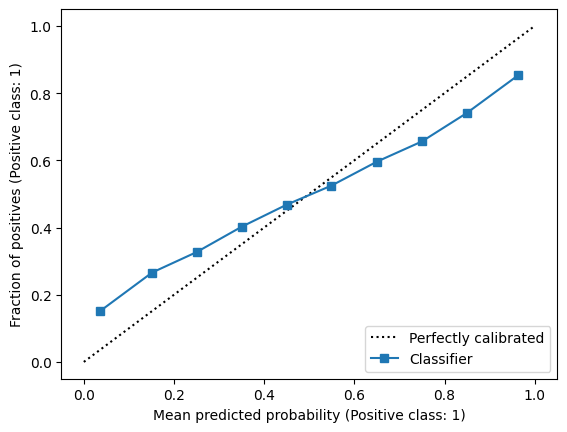

In [50]:
from sklearn.calibration import CalibrationDisplay
CalibrationDisplay.from_predictions(anal_data['playerA_wins'], anal_data['match_win_probA'], n_bins= 10)


### Confusion Matrix


In [51]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(anal_data["playerA_wins"], predicted_winnerA)
print(cm)


[[18027  8011]
 [ 8055 17573]]


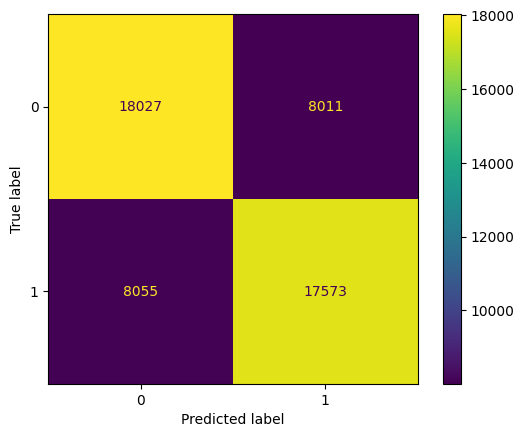

In [52]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(anal_data["playerA_wins"], predicted_winnerA)


### Histogram of Predicted Probabilities


(array([4755., 2427., 2149., 2321., 2319., 2363., 2451., 2354., 2490.,
        2453., 2469., 2338., 2441., 2397., 2405., 2368., 2203., 2127.,
        2391., 4445.]),
 array([3.35325729e-07, 5.00003035e-02, 1.00000272e-01, 1.50000240e-01,
        2.00000208e-01, 2.50000176e-01, 3.00000144e-01, 3.50000113e-01,
        4.00000081e-01, 4.50000049e-01, 5.00000017e-01, 5.49999985e-01,
        5.99999954e-01, 6.49999922e-01, 6.99999890e-01, 7.49999858e-01,
        7.99999826e-01, 8.49999794e-01, 8.99999763e-01, 9.49999731e-01,
        9.99999699e-01]),
 <BarContainer object of 20 artists>)

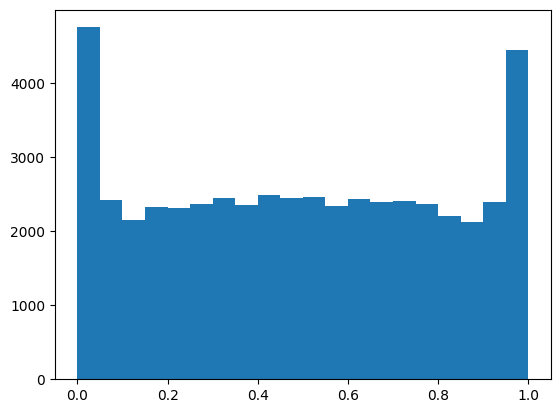

In [53]:
import matplotlib.pyplot as plt

plt.hist(anal_data["match_win_probA"], bins=20)


### ROC Curve


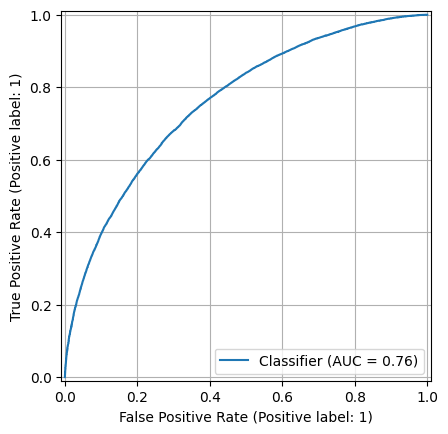

In [54]:
from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

RocCurveDisplay.from_predictions(anal_data["playerA_wins"], anal_data["match_win_probA"])
plt.grid(True)
plt.show()


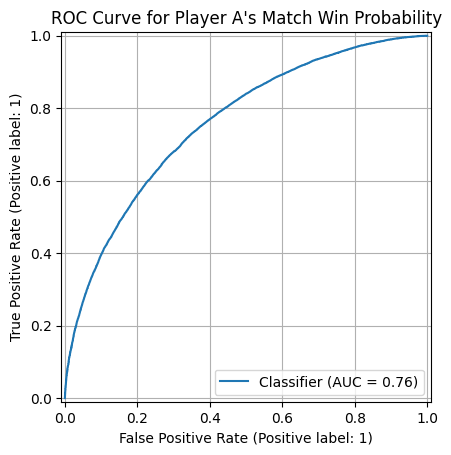

In [55]:
RocCurveDisplay.from_predictions(anal_data["playerA_wins"], anal_data["match_win_probA"])
plt.grid(True)
plt.title("ROC Curve for Player A's Match Win Probability")
plt.show()


### Saving the Predictions


In [56]:
results = pd.DataFrame({
    "playerA_win_actual": anal_data["playerA_wins"],
    "predicted_p": anal_data["p"],
    "predicted_q": anal_data["q"],
    "match_probabilityA": anal_data["match_win_probA"],
    "predicted_winner": predicted_winnerA
})

PATH = "/content/drive/MyDrive/Projects/Tennis/v1_1/v1_1_results.joblib"
joblib.dump(anal_data, PATH)


['/content/drive/MyDrive/Projects/Tennis/v1_1/v1_1_results.joblib']

# **SHAP Analysis**


## Data Check


In [57]:
from sklearn.preprocessing import StandardScaler
import gc

scaler = StandardScaler().fit(X_train_log)

X_val_log_scaled = scaler.transform(X_val_log)
X_val_log_scaled = pd.DataFrame(X_val_log_scaled, columns= X_val_log.columns, index= X_val_log.index)

# del X_val_log
gc.collect()


6684

In [58]:
print(X_val.shape)
print(X_val_log_scaled.shape)


(26109, 251)
(26109, 251)


In [59]:
print(list(X_val.columns) == list(X_val_log_scaled.columns))


True


In [60]:
assert (X_val.columns == X_val_log_scaled.columns).all()


## SHAP


### Importing Models


In [61]:
from sklearn.preprocessing import StandardScaler
import gc
X_train_val = pd.concat([X_train, X_val], axis = 0)
y_train_valA = pd.concat([y_trainA, y_valA], axis = 0)
y_train_valB = pd.concat([y_trainB, y_valB], axis = 0)

X_train_val_log = pd.concat([X_train_log, X_val_log], axis = 0)

scaler = StandardScaler()
X_train_val_log_scaled = scaler.fit_transform(X_train_val_log)
X_train_val_log_scaled = pd.DataFrame(X_train_val_log_scaled, columns= X_train_val_log.columns, index= X_train_val_log.index)
del X_train_val_log
gc.collect()

# Same frozen inverse-MAE weights as final testing; no test labels used.
import joblib
from sklearn.metrics import mean_absolute_error
val_preds = joblib.load(PROJECT_DIR / "v1_1_individual_model_prediction_dataframe.joblib")
maes = np.array([mean_absolute_error(val_preds["y_true"], val_preds[k])
                 for k in ("enet", "lightgbm", "xgboost", "catboost")])
inverse_weights = 1.0 / np.maximum(maes, 1e-12)
inverse_weights /= inverse_weights.sum()


In [62]:
import joblib
from google.colab import drive
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.linear_model import ElasticNet
from lightgbm import LGBMRegressor

drive.mount('/content/drive')
ENET_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/enet_final_playerA.pkl"
XGB_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/XGBoost_final_playerA.pkl"
LGB_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/lightGBM_final_playerA.pkl"
CAT_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/catBoost_final_playerA.pkl"

enet_A = joblib.load(ENET_PATH_A).named_steps["model"]
xgb_A = joblib.load(XGB_PATH_A)
lgbm_A = joblib.load(LGB_PATH_A)
cat_A = joblib.load(CAT_PATH_A)

xgb_A.fit(X_train_val, y_train_valA)
lgbm_A.fit(X_train_val, y_train_valA)
cat_A.fit(X_train_val, y_train_valA)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.557725 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 29211
[LightGBM] [Info] Number of data points in the train set: 207741, number of used features: 246
[LightGBM] [Info] Start training from score 0.620771
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[

CatBoostRegressor(depth=6, devices='0', iterations=1000, l2_leaf_reg=1, learning_rate=0.03, loss_function='RMSE', random_seed=42, task_type='CPU', verbose=False)

In [63]:
ENET_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/enet_final_playerB.pkl"
XGB_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/XGBoost_final_playerB.pkl"
LGB_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/lightGBM_final_playerB.pkl"
CAT_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/catBoost_final_playerB.pkl"

enet_B = joblib.load(ENET_PATH_B).named_steps["model"]
xgb_B = joblib.load(XGB_PATH_B)
lgbm_B = joblib.load(LGB_PATH_B)
cat_B = joblib.load(CAT_PATH_B)

xgb_B.fit(X_train_val, y_train_valB)
lgbm_B.fit(X_train_val, y_train_valB)
cat_B.fit(X_train_val, y_train_valB)


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 1.029756 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 29211
[LightGBM] [Info] Number of data points in the train set: 207741, number of used features: 246
[LightGBM] [Info] Start training from score 0.620826
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive ga

CatBoostRegressor(depth=6, devices='0', iterations=1000, l2_leaf_reg=1, learning_rate=0.03, loss_function='RMSE', random_seed=42, task_type='CPU', verbose=False)

### Explainer and Background Dataset


In [64]:
bg_normal = X_train_val.sample(2000, random_state= 42)
bg_log = X_train_val_log_scaled.sample(2000, random_state= 42)


In [65]:
X_explain_normal = X_train_val.tail(2000)
X_explain_log = X_train_val_log_scaled.tail(2000)


### Values (Player A)


In [66]:
import shap
import numpy as np


In [67]:
modelsA = {
    "LightGBM": {
        "model": lgbm_A,
        "background": bg_normal,
        "data": X_explain_normal,
        "explainer": "tree"
    },

    "XGBoost": {
        "model": xgb_A,
        "background": bg_normal,
        "data": X_explain_normal,
        "explainer": "tree"
    },

    "CatBoost": {
        "model": cat_A,
        "background": bg_normal,
        "data": X_explain_normal,
        "explainer": "tree"
    },

    "ElasticNet": {
        "model": enet_A,
        "background": bg_log,
        "data": X_explain_log,
        "explainer": "linear"
    }
}


In [68]:
shap_resultsA = {}

for name, cfg in modelsA.items():

    print(f"Computing SHAP for {name}...")

    if cfg["explainer"] == "tree":
        explainer = shap.TreeExplainer(cfg["model"])
    elif cfg["explainer"] == "linear":
        explainer = shap.LinearExplainer(cfg["model"], masker=cfg["background"])

    explanation = explainer(cfg["data"])

    shap_resultsA[name] = {
        "explanation": explanation,
        "values": explanation.values,
        "base_value": explanation.base_values
    }

    print(f"Done: {name}")


Computing SHAP for LightGBM...
Done: LightGBM
Computing SHAP for XGBoost...
Done: XGBoost
Computing SHAP for CatBoost...


Done: CatBoost
Computing SHAP for ElasticNet...
Done: ElasticNet


In [69]:
#test-1
shap_resultsA["LightGBM"]["values"]       
shap_resultsA["LightGBM"]["base_value"]   
shap_resultsA["LightGBM"]["explanation"]  


.values =
array([[ 3.94210146e-04,  0.00000000e+00,  9.84010741e-05, ...,
         0.00000000e+00,  0.00000000e+00, -1.99395207e-05],
       [ 3.14330008e-04,  0.00000000e+00, -6.13034384e-05, ...,
         0.00000000e+00,  0.00000000e+00, -1.00646581e-05],
       [ 3.92034040e-04,  0.00000000e+00, -5.41513439e-05, ...,
         0.00000000e+00,  0.00000000e+00, -2.34230059e-05],
       ...,
       [-1.49918129e-03,  0.00000000e+00,  9.34738628e-05, ...,
         0.00000000e+00,  0.00000000e+00, -8.61773738e-06],
       [-1.31487941e-03,  0.00000000e+00,  4.11574783e-04, ...,
         0.00000000e+00,  0.00000000e+00, -3.56793499e-06],
       [-1.82045107e-03,  0.00000000e+00,  9.94226470e-05, ...,
         0.00000000e+00,  0.00000000e+00, -1.09219899e-05]],
      shape=(2000, 251))

.base_values =
array([0.62079964, 0.62079964, 0.62079964, ..., 0.62079964, 0.62079964,
       0.62079964], shape=(2000,))

.data =
array([[ 32.,   3.,   2., ...,   0.,   1.,   0.],
       [ 32.,   3.,  36., 

In [70]:
ensemble_shap_valuesA = np.average([
        shap_resultsA["LightGBM"]["values"],
        shap_resultsA["XGBoost"]["values"],
        shap_resultsA["CatBoost"]["values"],
        shap_resultsA["ElasticNet"]["values"],
        ], axis=0, weights=inverse_weights[[1, 2, 3, 0]])


In [71]:
ensemble_base_valuesA = np.average([
        shap_resultsA["LightGBM"]["base_value"],
        shap_resultsA["XGBoost"]["base_value"],
        shap_resultsA["CatBoost"]["base_value"],
        shap_resultsA["ElasticNet"]["base_value"],
    ], axis=0, weights=inverse_weights[[1, 2, 3, 0]])


In [72]:
#SHAP Explanation Object
ensemble_explanationA = shap.Explanation(
    values=ensemble_shap_valuesA,
    base_values=ensemble_base_valuesA,
    data=X_explain_normal.values,
    feature_names=X_explain_normal.columns.tolist(),
)


In [73]:
#test-2
print(type(ensemble_explanationA))
print(ensemble_explanationA.values.shape)
print(len(ensemble_explanationA.feature_names))


<class 'shap._explanation.Explanation'>
(2000, 251)
251


In [74]:
#test-3
ensemble_predictionsA = np.average(np.stack([
    enet_A.predict(X_explain_log), lgbm_A.predict(X_explain_normal),
    xgb_A.predict(X_explain_normal), cat_A.predict(X_explain_normal)
]), axis=0, weights=inverse_weights)

reconstructed_predictionsA = ensemble_explanationA.base_values + ensemble_explanationA.values.sum(axis=1)


max_errorA = np.max(np.abs(ensemble_predictionsA - reconstructed_predictionsA))

print(f"Maximum reconstruction error: {max_errorA:.10f}")


Maximum reconstruction error: 0.0000003271


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(


In [75]:
#test-4
print(len(ensemble_explanationA.feature_names))
print(ensemble_explanationA.values.shape[1])


251
251


In [76]:
#test-5
print(ensemble_explanationA.values.shape)
print(ensemble_explanationA.data.shape)


(2000, 251)
(2000, 251)


### Values (Player B)


In [77]:
import numpy as np
import shap


In [78]:
modelsB = {
    "LightGBM": {
        "model": lgbm_B,
        "background": bg_normal,
        "data": X_explain_normal,
        "explainer": "tree"
    },

    "XGBoost": {
        "model": xgb_B,
        "background": bg_normal,
        "data": X_explain_normal,
        "explainer": "tree"
    },

    "CatBoost": {
        "model": cat_B,
        "background": bg_normal,
        "data": X_explain_normal,
        "explainer": "tree"
    },

    "ElasticNet": {
        "model": enet_B,
        "background": bg_log,
        "data": X_explain_log,
        "explainer": "linear"
    }
}


In [79]:
shap_resultsB = {}

for name, cfg in modelsB.items():

    print(f"Computing SHAP for {name}...")

    if cfg["explainer"] == "tree":
        explainer = shap.TreeExplainer(cfg["model"])
    elif cfg["explainer"] == "linear":
        explainer = shap.LinearExplainer(cfg["model"], masker=cfg["background"])

    explanation = explainer(cfg["data"])

    shap_resultsB[name] = {
        "explanation": explanation,
        "values": explanation.values,
        "base_value": explanation.base_values
    }

    print(f"Done: {name}")


Computing SHAP for LightGBM...
Done: LightGBM
Computing SHAP for XGBoost...
Done: XGBoost
Computing SHAP for CatBoost...


Done: CatBoost
Computing SHAP for ElasticNet...
Done: ElasticNet


In [80]:
#test-1
shap_resultsB["LightGBM"]["values"]       
shap_resultsB["LightGBM"]["base_value"]   
shap_resultsB["LightGBM"]["explanation"]  


.values =
array([[ 2.45172222e-04,  0.00000000e+00, -5.10708023e-04, ...,
        -1.91494572e-04,  0.00000000e+00,  1.01175978e-04],
       [ 4.76866131e-04,  0.00000000e+00, -8.66445642e-06, ...,
        -1.44413716e-04,  0.00000000e+00,  7.48024946e-05],
       [ 2.20175824e-04,  0.00000000e+00, -8.66445642e-06, ...,
        -1.65563972e-04,  0.00000000e+00,  9.20993711e-05],
       ...,
       [-2.37825484e-03,  0.00000000e+00,  4.48926820e-05, ...,
        -6.46716760e-05,  0.00000000e+00,  5.63006339e-05],
       [-1.77872995e-03,  0.00000000e+00,  2.96124421e-05, ...,
        -7.92467778e-05,  0.00000000e+00,  7.02036965e-05],
       [-1.61943860e-03,  0.00000000e+00,  4.94958186e-05, ...,
        -5.29925542e-05,  0.00000000e+00,  5.20150566e-05]],
      shape=(2000, 251))

.base_values =
array([0.62082907, 0.62082907, 0.62082907, ..., 0.62082907, 0.62082907,
       0.62082907], shape=(2000,))

.data =
array([[ 32.,   3.,   2., ...,   0.,   1.,   0.],
       [ 32.,   3.,  36., 

In [81]:
ensemble_shap_valuesB = np.average([
        shap_resultsB["LightGBM"]["values"],
        shap_resultsB["XGBoost"]["values"],
        shap_resultsB["CatBoost"]["values"],
        shap_resultsB["ElasticNet"]["values"],
        ], axis=0, weights=inverse_weights[[1, 2, 3, 0]])


In [82]:
ensemble_base_valuesB = np.average([
        shap_resultsB["LightGBM"]["base_value"],
        shap_resultsB["XGBoost"]["base_value"],
        shap_resultsB["CatBoost"]["base_value"],
        shap_resultsB["ElasticNet"]["base_value"],
    ], axis=0, weights=inverse_weights[[1, 2, 3, 0]])


In [83]:
#SHAP Explanation Object
ensemble_explanationB = shap.Explanation(
    values=ensemble_shap_valuesB,
    base_values=ensemble_base_valuesB,
    data=X_explain_normal.values,
    feature_names=X_explain_normal.columns.tolist(),
)


In [84]:
#test-2
print(type(ensemble_explanationB))
print(ensemble_explanationB.values.shape)
print(len(ensemble_explanationB.feature_names))


<class 'shap._explanation.Explanation'>
(2000, 251)
251


In [85]:
#test-3
ensemble_predictionsB = np.average(np.stack([
    enet_B.predict(X_explain_log), lgbm_B.predict(X_explain_normal),
    xgb_B.predict(X_explain_normal), cat_B.predict(X_explain_normal)
]), axis=0, weights=inverse_weights)

reconstructed_predictionsB = ensemble_explanationB.base_values + ensemble_explanationB.values.sum(axis=1)


max_errorB = np.max(np.abs(ensemble_predictionsB - reconstructed_predictionsB))

print(f"Maximum reconstruction error: {max_errorB:.10f}")


Maximum reconstruction error: 0.0000004193


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(


In [86]:
#test-4
print(len(ensemble_explanationB.feature_names))
print(ensemble_explanationB.values.shape[1])


251
251


In [87]:
#test-5
print(ensemble_explanationB.values.shape)
print(ensemble_explanationB.data.shape)


(2000, 251)
(2000, 251)


### Plots


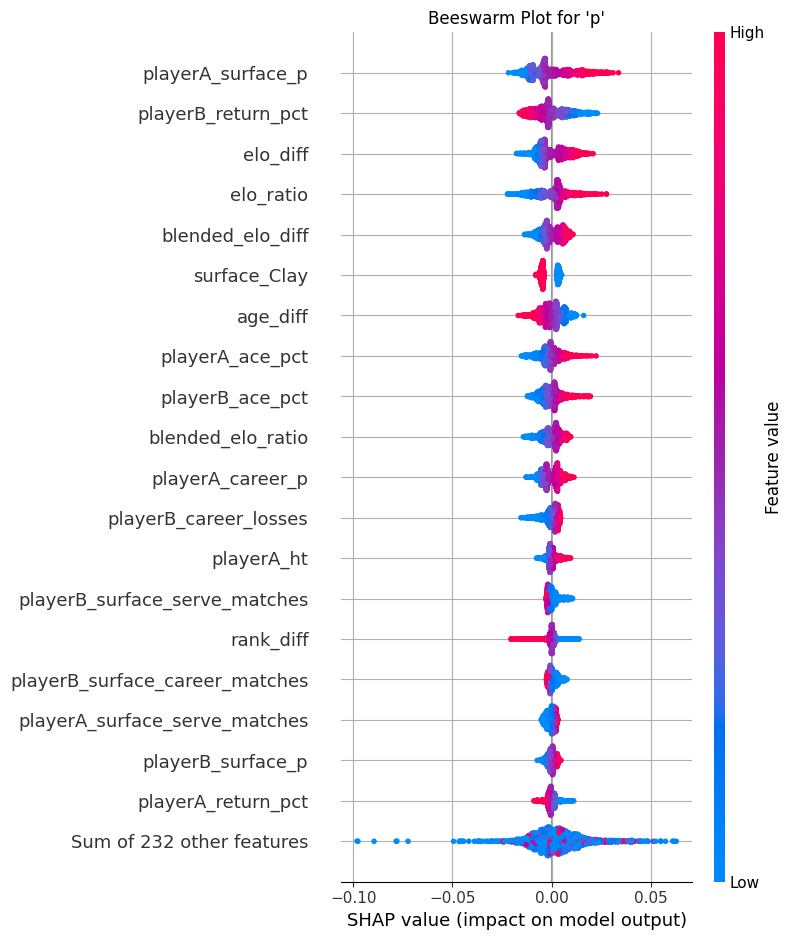

In [88]:
#Beeswarm player A
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

shap.plots.beeswarm(ensemble_explanationA, max_display=20, show=False)

plt.title("Beeswarm Plot for 'p'")
plt.grid()
plt.tight_layout()
plt.show()


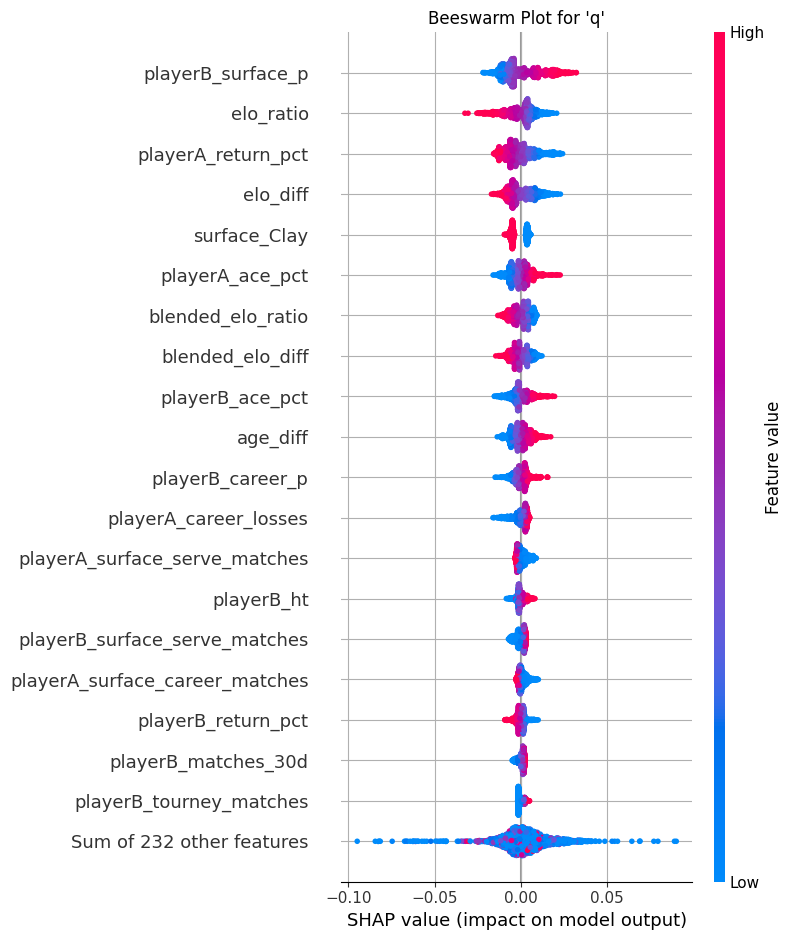

In [89]:
#Beeswarm player B
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

shap.plots.beeswarm(ensemble_explanationB, max_display=20, show=False)

plt.title("Beeswarm Plot for 'q'")
plt.grid()
plt.tight_layout()
plt.show()


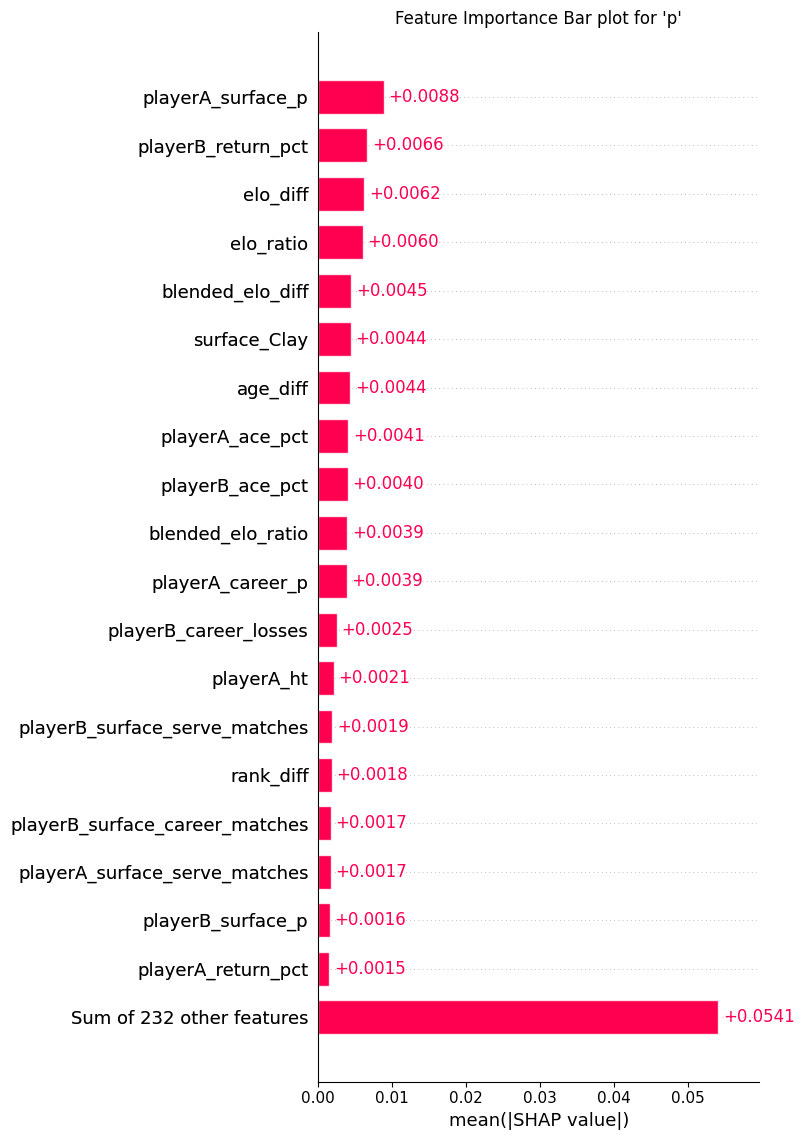

In [90]:
import numpy as np
import matplotlib.pyplot as plt
import shap

max_display = 20

plt.figure(figsize=(10, 8))

# 1. Generate the plot without rendering it immediately
shap.plots.bar(ensemble_explanationA, max_display=max_display, show=False)

# 2. Extract and sort the mean absolute SHAP values
values = np.abs(ensemble_explanationA.values).mean(0)
sorted_indices = np.argsort(values)[::-1]
sorted_values = values[sorted_indices]

# 3. Separate the top features from the remainder
# For max_display=20, the first 19 are shown individually, and the rest are summed
num_individual_features = max_display - 1
top_values = sorted_values[:num_individual_features]
remainder_sum = np.sum(sorted_values[num_individual_features:])

# 4. Get the text labels from the plot (ordered top-to-bottom)
ax = plt.gca()
labels = [t for t in ax.texts if t.get_text().startswith('+') or t.get_text().startswith('-')]

# 5. Correctly apply the precision formatting
for i, label in enumerate(labels):
    if i < len(top_values):
        # Individual features
        label.set_text(f"+{top_values[i]:.4f}")
    else:
        # The final summary bar at the bottom
        label.set_text(f"+{remainder_sum:.4f}")
        break  # Prevent updating any stray text elements

plt.title("Feature Importance Bar plot for 'p'")
plt.tight_layout()
plt.show()


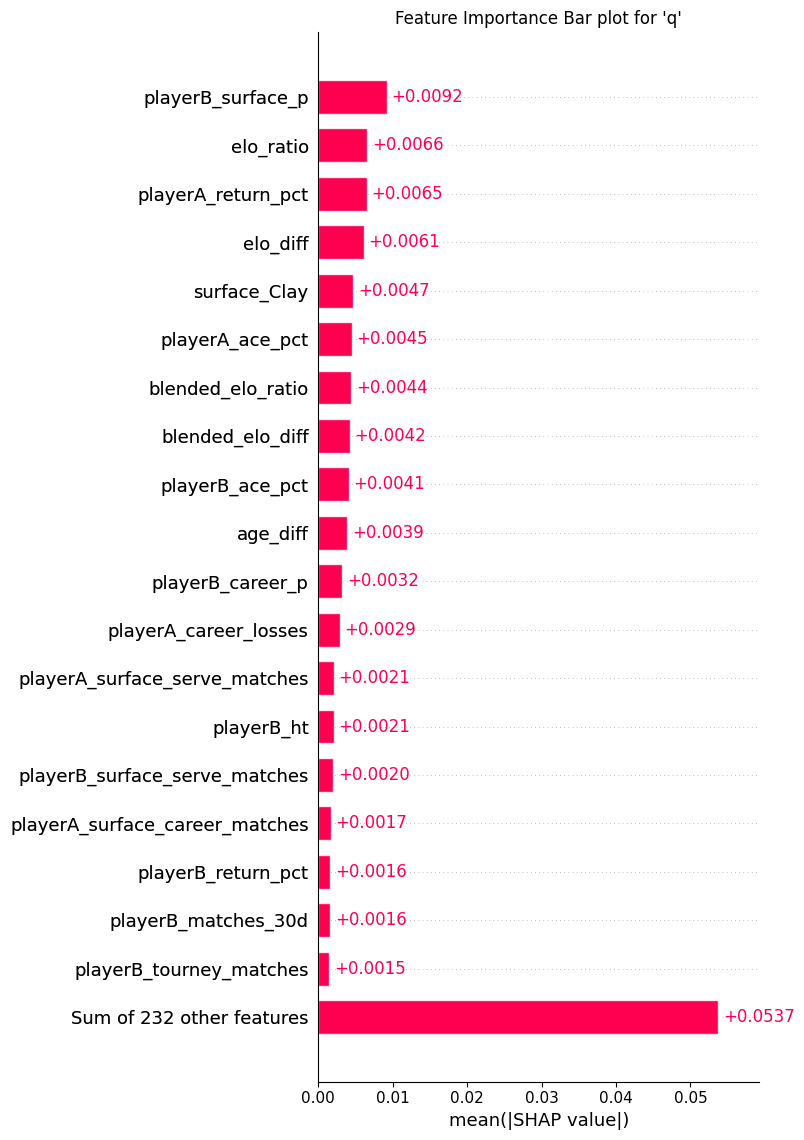

In [91]:
#player B
import numpy as np
import matplotlib.pyplot as plt
import shap

max_display = 20

plt.figure(figsize=(10, 8))

# 1. Generate the plot without rendering it immediately
shap.plots.bar(ensemble_explanationB, max_display=max_display, show=False)

# 2. Extract and sort the mean absolute SHAP values
values = np.abs(ensemble_explanationB.values).mean(0)
sorted_indices = np.argsort(values)[::-1]
sorted_values = values[sorted_indices]

# 3. Separate the top features from the remainder
# For max_display=20, the first 19 are shown individually, and the rest are summed
num_individual_features = max_display - 1
top_values = sorted_values[:num_individual_features]
remainder_sum = np.sum(sorted_values[num_individual_features:])

# 4. Get the text labels from the plot (ordered top-to-bottom)
ax = plt.gca()
labels = [t for t in ax.texts if t.get_text().startswith('+') or t.get_text().startswith('-')]

# 5. Correctly apply the precision formatting
for i, label in enumerate(labels):
    if i < len(top_values):
        # Individual features
        label.set_text(f"+{top_values[i]:.4f}")
    else:
        # The final summary bar at the bottom
        label.set_text(f"+{remainder_sum:.4f}")
        break  # Prevent updating any stray text elements

plt.title("Feature Importance Bar plot for 'q'")
plt.tight_layout()
plt.show()


### Feature Ranking Table 


In [92]:
#top 10 player A
mean_abs_shap = np.abs(ensemble_explanationA.values).mean(axis=0)

importance_dfA = (pd.DataFrame({"Feature": ensemble_explanationA.feature_names, "Mean |SHAP|": mean_abs_shap})
                 .sort_values("Mean |SHAP|", ascending=False).reset_index(drop=True))

top10 = importance_dfA.head(10)

print(top10)


              Feature  Mean |SHAP|
0   playerA_surface_p     0.008832
1  playerB_return_pct     0.006614
2            elo_diff     0.006249
3           elo_ratio     0.006020
4    blended_elo_diff     0.004496
5        surface_Clay     0.004392
6            age_diff     0.004359
7     playerA_ace_pct     0.004087
8     playerB_ace_pct     0.004023
9   blended_elo_ratio     0.003911


In [93]:
# Save as CSV 
PATH_CSV = "/content/drive/MyDrive/Projects/Tennis/v1_1/SHAP/v1_1_playerA_all_shap_importance.csv"
importance_dfA.to_csv(PATH_CSV, index=False)


In [94]:
#top 10 player B
mean_abs_shap = np.abs(ensemble_explanationB.values).mean(axis=0)

importance_dfB = (pd.DataFrame({"Feature": ensemble_explanationB.feature_names, "Mean |SHAP|": mean_abs_shap})
                 .sort_values("Mean |SHAP|", ascending=False).reset_index(drop=True))

top10 = importance_dfB.head(10)

print(top10)


              Feature  Mean |SHAP|
0   playerB_surface_p     0.009202
1           elo_ratio     0.006599
2  playerA_return_pct     0.006476
3            elo_diff     0.006127
4        surface_Clay     0.004667
5     playerA_ace_pct     0.004472
6   blended_elo_ratio     0.004436
7    blended_elo_diff     0.004225
8     playerB_ace_pct     0.004052
9            age_diff     0.003869


In [95]:
# Save as CSV 
PATH_CSV = "/content/drive/MyDrive/Projects/Tennis/v1_1/SHAP/v1_1_playerB_all_shap_importance.csv"
importance_dfB.to_csv(PATH_CSV, index=False)


### Feature Group Based Importance


In [96]:
feature_groups = {
    "Ranking": ["playerA_rank_filled", "playerB_rank_filled", "playerA_is_unranked", "playerB_is_unranked", "playerA_rank_points_missing", 
                "playerB_rank_points_missing", "rank_diff", "rank_ratio", "playerA_points_filled", "playerB_points_filled", "playerA_top10", 
                "playerB_top10", "playerA_top32", "playerB_top32", "playerA_top64", "playerB_top64", "playerA_top100", "playerB_top100"], 

    "Elo": ["playerA_elo", "playerB_elo", "elo_diff", "playerA_surface_elo", "playerB_surface_elo", "surface_elo_diff", 
            'playerA_blended_elo', 'playerB_blended_elo', 'blended_elo_diff', 'elo_ratio', 'playerA_elo_momentum', 'playerB_elo_momentum', 
            'playerA_elo_volatility', 'playerB_elo_volatility', 'blended_elo_ratio', 'surface_elo_ratio'], 

    "Form": ["playerA_last10_missing", "playerB_last10_missing", "playerA_last25_missing", "playerB_last25_missing",
             "playerA_surface10_missing", "playerB_surface10_missing", "playerA_surface25_missing", "playerB_surface25_missing", "playerA_last10_wins", 
             "playerB_last10_wins", "playerA_last10_matches", "playerB_last10_matches", "playerA_last10_pct", "playerB_last10_pct", 
             "playerA_last25_wins", "playerB_last25_wins", "playerA_last25_matches", "playerB_last25_matches", "playerA_last25_pct", 
             "playerB_last25_pct", "playerA_surface10_wins", "playerB_surface10_wins", "playerA_surface10_matches", 
             "playerB_surface10_matches", "playerA_surface10_pct", "playerB_surface10_pct", "playerA_surface25_wins", 
             "playerB_surface25_wins", "playerA_surface25_matches", "playerB_surface25_matches", "playerA_surface25_pct", 
             "playerB_surface25_pct", "playerA_52w_wins", "playerB_52w_wins", "playerA_52w_matches", "playerB_52w_matches", 
             "playerA_52w_pct", "playerB_52w_pct", "playerA_career_matches", "playerB_career_matches", "playerA_surface_career_matches", 
             "playerB_surface_career_matches", "playerA_last10_losses", "playerB_last10_losses", "playerA_last25_losses", 
             "playerB_last25_losses", "playerA_surface10_losses", "playerB_surface10_losses", "playerA_surface25_losses", 
             "playerB_surface25_losses", "playerA_52w_losses", "playerB_52w_losses"], 

    "Matchup": ["playerA_h2h_wins", "playerB_h2h_wins", "h2h_total", "h2h_diff", "playerA_surface_h2h_wins", "playerB_surface_h2h_wins", 
                "surface_h2h_total", "surface_h2h_diff", "playerA_last5_h2h_wins", "playerB_last5_h2h_wins", "last5_h2h_total", 
                "last5_h2h_diff", "last5_h2h_missing", "playerA_top20_wins", "playerB_top20_wins", "playerA_top20_losses", "playerB_top20_losses", 
                "playerA_top20_win_pct", "playerB_top20_win_pct", "playerA_hand_wins", "playerB_hand_wins", "playerA_hand_losses", 
                "playerB_hand_losses", "playerA_hand_win_pct", "playerB_hand_win_pct", 'playerA_top20_total', 'playerB_top20_total', 
                'playerA_hand_total', 'playerB_hand_total'], 

    "Fatigue": ["playerA_matches_30d", "playerB_matches_30d",
                "playerA_wins_30d", "playerB_wins_30d", "playerA_losses_30d", "playerB_losses_30d",
                "playerA_winpct_30d", "playerB_winpct_30d", "playerA_matches_60d", "playerB_matches_60d",
                "playerA_tournaments_5w", "playerB_tournaments_5w",
                "playerA_tournaments_10w", "playerB_tournaments_10w"],

    "Serve": ["playerA_ace_pct", "playerB_ace_pct", "playerA_df_pct", "playerB_df_pct", "playerA_1stIn_pct", "playerB_1stIn_pct", 
              "playerA_1stWon_pct", "playerB_1stWon_pct", "playerA_2ndWon_pct", "playerB_2ndWon_pct", "playerA_career_p", 
              "playerB_career_p", "playerA_serve_matches", "playerB_serve_matches", "playerA_matchup_p", "playerB_matchup_p", 
              "playerA_matchup_service_points", "playerB_matchup_service_points", "playerA_surface_p", "playerB_surface_p", 
              "playerA_surface_serve_matches", "playerB_surface_serve_matches"], 

    "Return": ["playerA_return_pct", "playerB_return_pct", "playerA_bp_convert_pct", "playerB_bp_convert_pct", "playerA_return_matches", 
               "playerB_return_matches"], 

    "Physical":  ['playerA_hand_A', 'playerA_hand_L', 'playerA_hand_R', 'playerA_hand_U', 'playerB_hand_A', 'playerB_hand_L', 
                  'playerB_hand_R','playerB_hand_U', "playerA_age", "playerB_age", "age_diff", "playerA_ht", "playerB_ht", "height_diff"],

    "Seed":  ["playerA_seeded", "playerB_seeded", "seed_diff", "seed_diff_missing"], 

    "Surface Specialization": ["playerA_win_rate_specialization", "playerB_win_rate_specialization", "playerA_elo_specialization", 
                               "playerB_elo_specialization", "playerA_serve_specialization", "playerB_serve_specialization"],

    "Experience": ["playerA_career_wins", "playerB_career_wins", "playerA_career_losses", "playerB_career_losses", "playerA_career_matches",
                    "playerA_career_pct", "playerB_career_matches", "playerA_surface_career_matches", "playerB_surface_career_matches",
                    "playerB_career_pct", "playerA_surface_career_wins", "playerB_surface_career_wins", "playerA_surface_career_losses", 
                    "playerB_surface_career_losses", "playerA_surface_career_pct", "playerB_surface_career_pct","playerA_level_wins", 
                    "playerB_level_wins", "playerA_level_losses", "playerB_level_losses", "playerA_level_win_pct", 
                   "playerA_tourney_matches", "playerB_tourney_matches", "playerA_tourney_appearances", "playerB_tourney_appearances", "playerA_level_matches", "playerB_level_matches", 
                   "playerB_level_win_pct"], 

    "Tournament Context": ["draw_size", "best_of", 'playerA_entry_ALT', 'playerA_entry_ITF', 'playerA_entry_LL', 
                           'playerA_entry_NONE', 'playerA_entry_OTHER', 'playerA_entry_PR', 'playerA_entry_Q', 'playerA_entry_SE', 
                           'playerA_entry_WC', 'playerB_entry_ALT', 'playerB_entry_ITF', 'playerB_entry_LL', 'playerB_entry_NONE', 
                           'playerB_entry_OTHER', 'playerB_entry_PR', 'playerB_entry_Q', 'playerB_entry_SE', 'playerB_entry_WC',
                           'round_BR', 'round_ER', 'round_F', 'round_Q1', 'round_Q2', 'round_Q3', 'round_QF', 'round_R128', 'round_R16', 
                           'round_R32', 'round_R64', 'round_RR', 'round_SF', 'tourney_level_A', 'tourney_level_C', 'tourney_level_D', 
                           'tourney_level_F', 'tourney_level_G', 'tourney_level_M', 'surface_Carpet', 'surface_Clay', 'surface_Grass', 
                           'surface_Hard',]
}


In [97]:
group_importanceA = {}

for group_name, features in feature_groups.items():
    cols = [
        ensemble_explanationA.feature_names.index(f)
        for f in features
        if f in ensemble_explanationA.feature_names
    ]

    group_importanceA[group_name] = (np.abs(ensemble_explanationA.values[:, cols]).mean(axis=0).sum())


group_importanceB = {}

for group_name, features in feature_groups.items():
    cols = [
        ensemble_explanationB.feature_names.index(f)
        for f in features
        if f in ensemble_explanationB.feature_names
    ]

    group_importanceB[group_name] = (np.abs(ensemble_explanationB.values[:, cols]).mean(axis=0).sum())


In [98]:
group_dfA = (pd.DataFrame({
        "Feature Group": group_importanceA.keys(),
        "Importance": group_importanceA.values()
    })
    .sort_values("Importance", ascending=False)
    )

group_dfB = (pd.DataFrame({
        "Feature Group": group_importanceB.keys(),
        "Importance": group_importanceB.values()
    })
    .sort_values("Importance", ascending=False)
    )


In [99]:
group_dfA["Percentage"] = 100*group_dfA["Importance"]/group_dfA["Importance"].sum()
group_dfB["Percentage"] = 100*group_dfB["Importance"]/group_dfB["Importance"].sum()


In [100]:
PATH_CSV_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/SHAP/v1_1_playerA_groupwise_shap_importance.csv"
group_dfA.to_csv(PATH_CSV_A,index=False)

PATH_CSV_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/SHAP/v1_1_playerB_groupwise_shap_importance.csv"
group_dfB.to_csv(PATH_CSV_B,index=False)


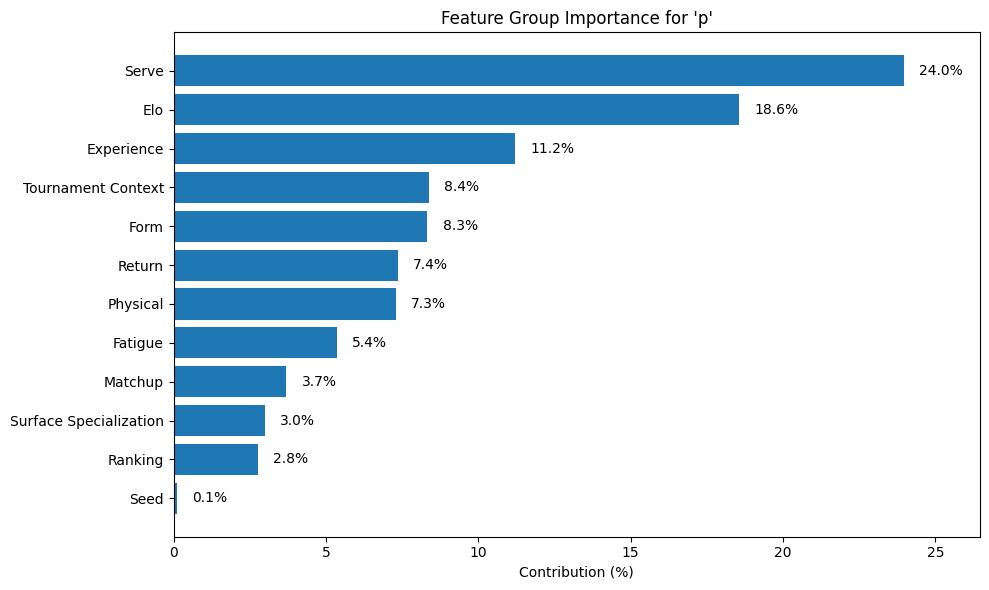

In [101]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Create the horizontal bar chart
bars = plt.barh(group_dfA["Feature Group"], group_dfA["Percentage"])

# Add labels
plt.xlabel("Contribution (%)")
plt.title("Feature Group Importance for 'p'")
plt.gca().invert_yaxis() # Highest percentage at the top

# Add percentage text in front of each bar
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.5,                          # x-position (slightly to the right of the bar)
        bar.get_y() + bar.get_height() / 2,  # y-position (center of the bar)
        f'{width:.1f}%',                      # format to 1 decimal place
        va='center'                            # vertical alignment
    )

# --- FIX: Dynamically add extra breathing room to the right side ---
max_width = group_dfA["Percentage"].max()
plt.xlim(0, max_width + 2.5)  # Adds a 2.5% padding margin past the longest bar

# plt.grid()
plt.tight_layout()
plt.show()


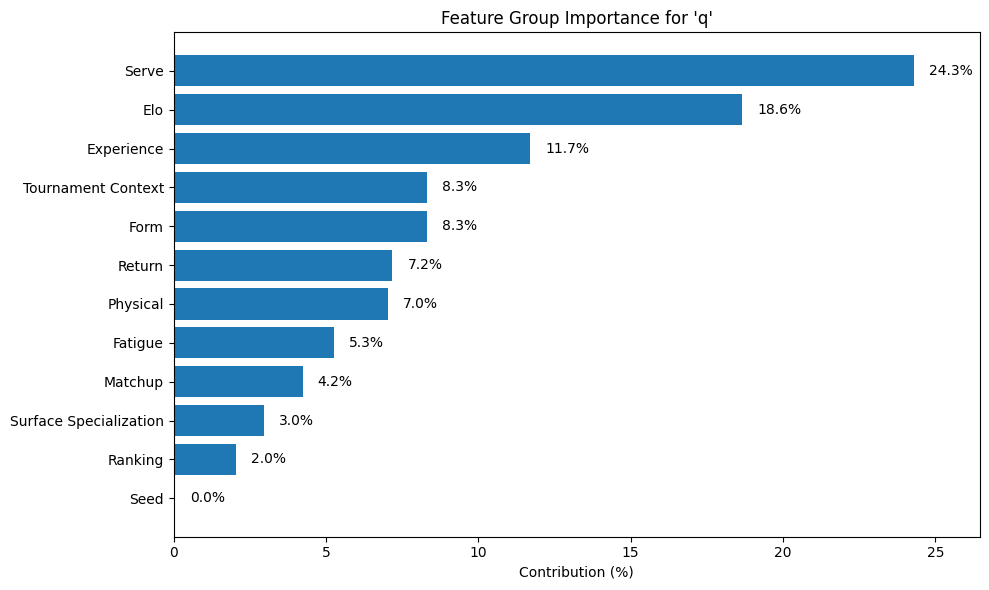

In [102]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

# Create the horizontal bar chart
bars = plt.barh(group_dfB["Feature Group"], group_dfB["Percentage"])

# Add labels
plt.xlabel("Contribution (%)")
plt.title("Feature Group Importance for 'q'")
plt.gca().invert_yaxis() # Highest percentage at the top

# Add percentage text in front of each bar
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.5,                          # x-position (slightly to the right of the bar)
        bar.get_y() + bar.get_height() / 2,  # y-position (center of the bar)
        f'{width:.1f}%',                      # format to 1 decimal place
        va='center'                            # vertical alignment
    )

# --- FIX: Dynamically add extra breathing room to the right side ---
max_width = group_dfA["Percentage"].max()
plt.xlim(0, max_width + 2.5)  # Adds a 2.5% padding margin past the longest bar

# plt.grid()
plt.tight_layout()
plt.show()


In [103]:
list(X_train.columns)


['draw_size',
 'best_of',
 'playerA_seed',
 'playerB_seed',
 'playerA_ht',
 'playerB_ht',
 'playerA_age',
 'playerB_age',
 'playerA_rank_points',
 'playerB_rank_points',
 'playerA_h2h_wins',
 'playerB_h2h_wins',
 'h2h_total',
 'h2h_diff',
 'playerA_surface_h2h_wins',
 'playerB_surface_h2h_wins',
 'surface_h2h_total',
 'surface_h2h_diff',
 'playerA_last5_h2h_wins',
 'playerB_last5_h2h_wins',
 'last5_h2h_total',
 'last5_h2h_diff',
 'playerA_top20_wins',
 'playerA_top20_losses',
 'playerA_top20_total',
 'playerA_top20_win_pct',
 'playerB_top20_wins',
 'playerB_top20_losses',
 'playerB_top20_total',
 'playerB_top20_win_pct',
 'playerA_hand_wins',
 'playerA_hand_losses',
 'playerA_hand_total',
 'playerA_hand_win_pct',
 'playerB_hand_wins',
 'playerB_hand_losses',
 'playerB_hand_total',
 'playerB_hand_win_pct',
 'playerA_elo',
 'playerB_elo',
 'elo_diff',
 'playerA_surface_elo',
 'playerB_surface_elo',
 'surface_elo_diff',
 'playerA_blended_elo',
 'playerB_blended_elo',
 'blended_elo_diff',


# **Permutation**


In [104]:
import numpy as np

class InverseMAEWeightedEnsemble:
    def __init__(self, lightgbm, xgboost, catboost, enet, weights):
        self.lightgbm = lightgbm
        self.xgboost = xgboost
        self.catboost = catboost
        self.enet = enet
        self.weights = np.asarray(weights)

    def predict(self, X_normal, X_log):
        predictions = np.stack([
            np.clip(self.enet.predict(X_log), 0, 1),
            np.clip(self.lightgbm.predict(X_normal), 0, 1),
            np.clip(self.xgboost.predict(X_normal), 0, 1),
            np.clip(self.catboost.predict(X_normal), 0, 1)
        ])
        return np.average(predictions, axis=0, weights=self.weights)


### Loading Models


In [105]:
from sklearn.preprocessing import StandardScaler
import gc
X_train_val = pd.concat([X_train, X_val], axis = 0)
y_train_valA = pd.concat([y_trainA, y_valA], axis = 0)
y_train_valB = pd.concat([y_trainB, y_valB], axis = 0)

X_train_val_log = pd.concat([X_train_log, X_val_log], axis = 0)

scaler = StandardScaler()
X_train_val_log_scaled = scaler.fit_transform(X_train_val_log)
X_train_val_log_scaled = pd.DataFrame(X_train_val_log_scaled, columns= X_train_val_log.columns, index= X_train_val_log.index)
del X_train_val_log
gc.collect()

# Same frozen inverse-MAE weights as final testing; no test labels used.
import joblib
from sklearn.metrics import mean_absolute_error
val_preds = joblib.load(PROJECT_DIR / "v1_1_individual_model_prediction_dataframe.joblib")
maes = np.array([mean_absolute_error(val_preds["y_true"], val_preds[k])
                 for k in ("enet", "lightgbm", "xgboost", "catboost")])
inverse_weights = 1.0 / np.maximum(maes, 1e-12)
inverse_weights /= inverse_weights.sum()


In [106]:
import joblib
from google.colab import drive
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
from sklearn.linear_model import ElasticNet
from lightgbm import LGBMRegressor

drive.mount('/content/drive')
ENET_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/enet_final_playerA.pkl"
XGB_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/XGBoost_final_playerA.pkl"
LGB_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/lightGBM_final_playerA.pkl"
CAT_PATH_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/catBoost_final_playerA.pkl"

enet_A = joblib.load(ENET_PATH_A).named_steps["model"]
xgb_A = joblib.load(XGB_PATH_A)
lgbm_A = joblib.load(LGB_PATH_A)
cat_A = joblib.load(CAT_PATH_A)

xgb_A.fit(X_train_val, y_train_valA)
lgbm_A.fit(X_train_val, y_train_valA)
cat_A.fit(X_train_val, y_train_valA)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.546778 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 29211
[LightGBM] [Info] Number of data points in the train set: 207741, number of used features: 246
[LightGBM] [Info] Start training from score 0.620771
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[

CatBoostRegressor(depth=6, devices='0', iterations=1000, l2_leaf_reg=1, learning_rate=0.03, loss_function='RMSE', random_seed=42, task_type='CPU', verbose=False)

In [107]:
ENET_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/enet_final_playerB.pkl"
XGB_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/XGBoost_final_playerB.pkl"
LGB_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/lightGBM_final_playerB.pkl"
CAT_PATH_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/models/catBoost_final_playerB.pkl"

enet_B = joblib.load(ENET_PATH_B).named_steps["model"]
xgb_B = joblib.load(XGB_PATH_B)
lgbm_B = joblib.load(LGB_PATH_B)
cat_B = joblib.load(CAT_PATH_B)

xgb_B.fit(X_train_val, y_train_valB)
lgbm_B.fit(X_train_val, y_train_valB)
cat_B.fit(X_train_val, y_train_valB)


[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.567646 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 29211
[LightGBM] [Info] Number of data points in the train set: 207741, number of used features: 246
[LightGBM] [Info] Start training from score 0.620826
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive ga

CatBoostRegressor(depth=6, devices='0', iterations=1000, l2_leaf_reg=1, learning_rate=0.03, loss_function='RMSE', random_seed=42, task_type='CPU', verbose=False)

### Explainer and Background Dataset


In [108]:
bg_normal = X_train_val.sample(2000, random_state= 42)
bg_log = X_train_val_log_scaled.sample(2000, random_state= 42)


In [109]:
X_explain_normal = X_train_val.tail(2000)
X_explain_log = X_train_val_log_scaled.tail(2000)

y_explainA= y_train_valA.tail(2000)
y_explainB= y_train_valB.tail(2000)


### Baseline Score


In [110]:
from sklearn.metrics import mean_absolute_error

ensembleA = InverseMAEWeightedEnsemble(lgbm_A, xgb_A, cat_A, enet_A, inverse_weights)

baseline_predictionsA = ensembleA.predict(X_explain_normal, X_explain_log)

baseline_maeA = mean_absolute_error(y_explainA, baseline_predictionsA)

print(baseline_maeA)


0.06132741651236899


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(


In [111]:
from sklearn.metrics import mean_absolute_error

ensembleB = InverseMAEWeightedEnsemble(lgbm_B, xgb_B, cat_B, enet_B, inverse_weights)

baseline_predictionsB = ensembleB.predict(X_explain_normal, X_explain_log)

baseline_maeB = mean_absolute_error(y_explainB, baseline_predictionsB)

print(baseline_maeB)


0.061472771955934605


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(


### Permutation Loop


In [112]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

# 1. Define the number of repeats for stability
n_repeats = 10
feature_importanceA = []
features = X_explain_normal.columns

# 3. Main Permutation Loop
for feature in features:
    mae_increases = []
    
    # Get the column index
    col_idx = X_explain_normal.columns.get_loc(feature)
    
    for repeat in range(n_repeats):
        # Create copies to avoid modifying original data
        X_test_permuted = X_explain_normal.copy()
        X_log_permuted = X_explain_log.copy()
        
        # Generate random permutation indices
        perm_indices = np.random.permutation(len(X_explain_normal))
        
        # Apply the SAME permutation to the specific column in both matrices
        X_test_permuted.iloc[:, col_idx] = X_test_permuted.iloc[perm_indices, col_idx].values
        X_log_permuted.iloc[:, col_idx] = X_log_permuted.iloc[perm_indices, col_idx].values
        
        # Predict with permuted data
        permuted_preds = ensembleA.predict(X_test_permuted, X_log_permuted)
        
        # Calculate new MAE and the increase
        permuted_mae = mean_absolute_error(y_explainA, permuted_preds)
        mae_increases.append(permuted_mae - baseline_maeA)
    
    # Store average importance for this feature
    feature_importanceA.append(np.mean(mae_increases))
    print(f"Finished {feature}")

# 4. Create the DataFrame
pfi_dfA = pd.DataFrame({
    "Feature": features,
    "Permutation Importance": feature_importanceA}).sort_values("Permutation Importance", ascending=False).reset_index(drop=True)

PATH_CSV_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/Permutation/v1_1_playerA_permutation_importance.csv"
pfi_dfA.to_csv(PATH_CSV_A, index= False)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted w

Finished draw_size


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted w

Finished best_of


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted w

Finished playerA_seed


... (492 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted w

Finished playerB_hand_R


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted w

Finished playerB_hand_U


In [113]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

# 1. Define the number of repeats for stability
n_repeats = 10
feature_importanceB = []
features = X_explain_normal.columns

# 3. Main Permutation Loop
for feature in features:
    mae_increases = []
    
    # Get the column index
    col_idx = X_explain_normal.columns.get_loc(feature)
    
    for repeat in range(n_repeats):
        # Create copies to avoid modifying original data
        X_test_permuted = X_explain_normal.copy()
        X_log_permuted = X_explain_log.copy()
        
        # Generate random permutation indices
        perm_indices = np.random.permutation(len(X_explain_normal))
        
        # Apply the SAME permutation to the specific column in both matrices
        X_test_permuted.iloc[:, col_idx] = X_test_permuted.iloc[perm_indices, col_idx].values
        X_log_permuted.iloc[:, col_idx] = X_log_permuted.iloc[perm_indices, col_idx].values
        
        # Predict with permuted data
        permuted_preds = ensembleB.predict(X_test_permuted, X_log_permuted)
        
        # Calculate new MAE and the increase
        permuted_mae = mean_absolute_error(y_explainB, permuted_preds)
        mae_increases.append(permuted_mae - baseline_maeB)
    
    # Store average importance for this feature
    feature_importanceB.append(np.mean(mae_increases))
    print(f"Finished {feature}")

# 4. Create the DataFrame
pfi_dfB = pd.DataFrame({
    "Feature": features,
    "Permutation Importance": feature_importanceB}).sort_values("Permutation Importance", ascending=False).reset_index(drop=True)

PATH_CSV_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/Permutation/v1_1_playerB_permutation_importance.csv"
pfi_dfB.to_csv(PATH_CSV_B, index= False)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted w

Finished draw_size


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted w

Finished best_of


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted w

Finished playerA_seed


... (492 outputs left out)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted w

Finished playerB_hand_R


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but ElasticNet was fitted w

Finished playerB_hand_U


### Plots


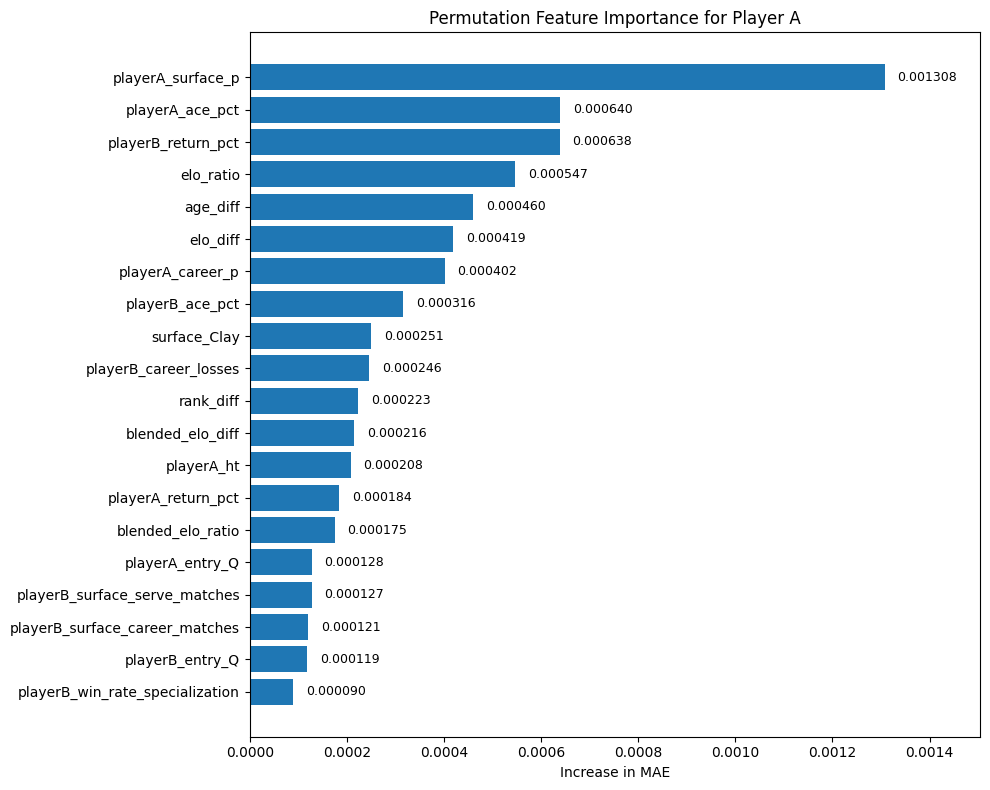

In [114]:
import matplotlib.pyplot as plt

# 1. Prepare data
top20 = pfi_dfA.head(20).iloc[::-1]  # Reverse for bottom-to-top plotting

plt.figure(figsize=(10, 8))

# 2. Create the bar chart
bars = plt.barh(top20["Feature"], top20["Permutation Importance"])

# 3. Add dynamic gap
# We set the label position at a small percentage of the max value
max_val = top20["Permutation Importance"].max()
offset = max_val * 0.02  # 2% gap from the end of the bar

# 4. Loop through bars to place text
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + offset,         # x-position (bar end + gap)
        bar.get_y() + bar.get_height()/2,  # y-position (center of bar)
        f'{width:.6f}',         # value formatted to 4 decimal places
        va='center',            # vertical alignment
        fontsize=9
    )

# 5. Styling
plt.xlabel("Increase in MAE")
plt.title("Permutation Feature Importance for Player A")
# Adjust x-limit to ensure labels don't get clipped by the right boundary
plt.xlim(0, max_val * 1.15) 

plt.tight_layout()
plt.show()


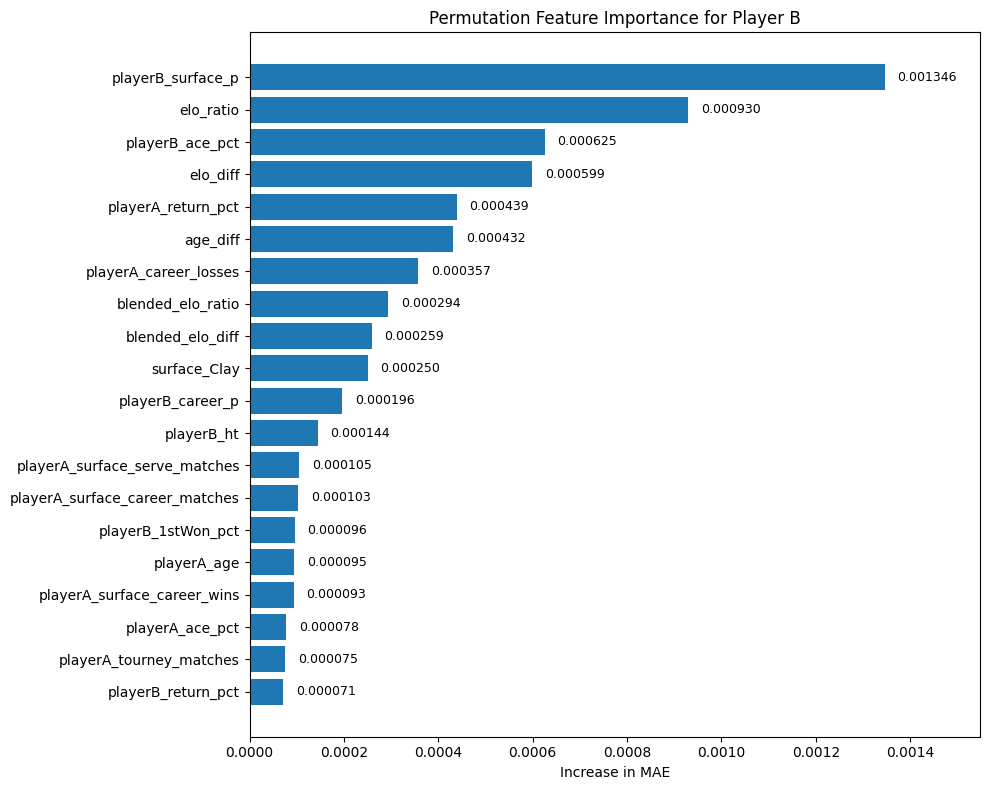

In [115]:
import matplotlib.pyplot as plt

# 1. Prepare data
top20 = pfi_dfB.head(20).iloc[::-1]  # Reverse for bottom-to-top plotting

plt.figure(figsize=(10, 8))

# 2. Create the bar chart
bars = plt.barh(top20["Feature"], top20["Permutation Importance"])

# 3. Add dynamic gap
# We set the label position at a small percentage of the max value
max_val = top20["Permutation Importance"].max()
offset = max_val * 0.02  # 2% gap from the end of the bar

# 4. Loop through bars to place text
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + offset,         # x-position (bar end + gap)
        bar.get_y() + bar.get_height()/2,  # y-position (center of bar)
        f'{width:.6f}',         # value formatted to 4 decimal places
        va='center',            # vertical alignment
        fontsize=9
    )

# 5. Styling
plt.xlabel("Increase in MAE")
plt.title("Permutation Feature Importance for Player B")
# Adjust x-limit to ensure labels don't get clipped by the right boundary
plt.xlim(0, max_val * 1.15) 

plt.tight_layout()
plt.show()


### Feature Group Importance


In [116]:
feature_groups = {
    "Ranking": ["playerA_rank_filled", "playerB_rank_filled", "playerA_is_unranked", "playerB_is_unranked", "playerA_rank_points_missing", 
                "playerB_rank_points_missing", "rank_diff", "rank_ratio", "playerA_points_filled", "playerB_points_filled", "playerA_top10", 
                "playerB_top10", "playerA_top32", "playerB_top32", "playerA_top64", "playerB_top64", "playerA_top100", "playerB_top100"], 

    "Elo": ["playerA_elo", "playerB_elo", "elo_diff", "playerA_surface_elo", "playerB_surface_elo", "surface_elo_diff", 
            'playerA_blended_elo', 'playerB_blended_elo', 'blended_elo_diff', 'elo_ratio', 'playerA_elo_momentum', 'playerB_elo_momentum', 
            'playerA_elo_volatility', 'playerB_elo_volatility', 'blended_elo_ratio', 'surface_elo_ratio'], 

    "Form": ["playerA_last10_missing", "playerB_last10_missing", "playerA_last25_missing", "playerB_last25_missing",
             "playerA_surface10_missing", "playerB_surface10_missing", "playerA_surface25_missing", "playerB_surface25_missing", "playerA_last10_wins", 
             "playerB_last10_wins", "playerA_last10_matches", "playerB_last10_matches", "playerA_last10_pct", "playerB_last10_pct", 
             "playerA_last25_wins", "playerB_last25_wins", "playerA_last25_matches", "playerB_last25_matches", "playerA_last25_pct", 
             "playerB_last25_pct", "playerA_surface10_wins", "playerB_surface10_wins", "playerA_surface10_matches", 
             "playerB_surface10_matches", "playerA_surface10_pct", "playerB_surface10_pct", "playerA_surface25_wins", 
             "playerB_surface25_wins", "playerA_surface25_matches", "playerB_surface25_matches", "playerA_surface25_pct", 
             "playerB_surface25_pct", "playerA_52w_wins", "playerB_52w_wins", "playerA_52w_matches", "playerB_52w_matches", 
             "playerA_52w_pct", "playerB_52w_pct", "playerA_career_matches", "playerB_career_matches", "playerA_surface_career_matches", 
             "playerB_surface_career_matches", "playerA_last10_losses", "playerB_last10_losses", "playerA_last25_losses", 
             "playerB_last25_losses", "playerA_surface10_losses", "playerB_surface10_losses", "playerA_surface25_losses", 
             "playerB_surface25_losses", "playerA_52w_losses", "playerB_52w_losses"], 

    "Matchup": ["playerA_h2h_wins", "playerB_h2h_wins", "h2h_total", "h2h_diff", "playerA_surface_h2h_wins", "playerB_surface_h2h_wins", 
                "surface_h2h_total", "surface_h2h_diff", "playerA_last5_h2h_wins", "playerB_last5_h2h_wins", "last5_h2h_total", 
                "last5_h2h_diff", "last5_h2h_missing", "playerA_top20_wins", "playerB_top20_wins", "playerA_top20_losses", "playerB_top20_losses", 
                "playerA_top20_win_pct", "playerB_top20_win_pct", "playerA_hand_wins", "playerB_hand_wins", "playerA_hand_losses", 
                "playerB_hand_losses", "playerA_hand_win_pct", "playerB_hand_win_pct", 'playerA_top20_total', 'playerB_top20_total', 
                'playerA_hand_total', 'playerB_hand_total'], 

    "Fatigue": ["playerA_matches_30d", "playerB_matches_30d",
                "playerA_wins_30d", "playerB_wins_30d", "playerA_losses_30d", "playerB_losses_30d",
                "playerA_winpct_30d", "playerB_winpct_30d", "playerA_matches_60d", "playerB_matches_60d",
                "playerA_tournaments_5w", "playerB_tournaments_5w",
                "playerA_tournaments_10w", "playerB_tournaments_10w"],

    "Serve": ["playerA_ace_pct", "playerB_ace_pct", "playerA_df_pct", "playerB_df_pct", "playerA_1stIn_pct", "playerB_1stIn_pct", 
              "playerA_1stWon_pct", "playerB_1stWon_pct", "playerA_2ndWon_pct", "playerB_2ndWon_pct", "playerA_career_p", 
              "playerB_career_p", "playerA_serve_matches", "playerB_serve_matches", "playerA_matchup_p", "playerB_matchup_p", 
              "playerA_matchup_service_points", "playerB_matchup_service_points", "playerA_surface_p", "playerB_surface_p", 
              "playerA_surface_serve_matches", "playerB_surface_serve_matches"], 

    "Return": ["playerA_return_pct", "playerB_return_pct", "playerA_bp_convert_pct", "playerB_bp_convert_pct", "playerA_return_matches", 
               "playerB_return_matches"], 

    "Physical":  ['playerA_hand_A', 'playerA_hand_L', 'playerA_hand_R', 'playerA_hand_U', 'playerB_hand_A', 'playerB_hand_L', 
                  'playerB_hand_R','playerB_hand_U', "playerA_age", "playerB_age", "age_diff", "playerA_ht", "playerB_ht", "height_diff"],

    "Seed":  ["playerA_seeded", "playerB_seeded", "seed_diff", "seed_diff_missing"], 

    "Surface Specialization": ["playerA_win_rate_specialization", "playerB_win_rate_specialization", "playerA_elo_specialization", 
                               "playerB_elo_specialization", "playerA_serve_specialization", "playerB_serve_specialization"],

    "Experience": ["playerA_career_wins", "playerB_career_wins", "playerA_career_losses", "playerB_career_losses", "playerA_career_matches",
                    "playerA_career_pct", "playerB_career_matches", "playerA_surface_career_matches", "playerB_surface_career_matches",
                    "playerB_career_pct", "playerA_surface_career_wins", "playerB_surface_career_wins", "playerA_surface_career_losses", 
                    "playerB_surface_career_losses", "playerA_surface_career_pct", "playerB_surface_career_pct","playerA_level_wins", 
                    "playerB_level_wins", "playerA_level_losses", "playerB_level_losses", "playerA_level_win_pct", 
                   "playerA_tourney_matches", "playerB_tourney_matches", "playerA_tourney_appearances", "playerB_tourney_appearances", "playerA_level_matches", "playerB_level_matches", 
                   "playerB_level_win_pct"], 

    "Tournament Context": ["draw_size", "best_of", 'playerA_entry_ALT', 'playerA_entry_ITF', 'playerA_entry_LL', 
                           'playerA_entry_NONE', 'playerA_entry_OTHER', 'playerA_entry_PR', 'playerA_entry_Q', 'playerA_entry_SE', 
                           'playerA_entry_WC', 'playerB_entry_ALT', 'playerB_entry_ITF', 'playerB_entry_LL', 'playerB_entry_NONE', 
                           'playerB_entry_OTHER', 'playerB_entry_PR', 'playerB_entry_Q', 'playerB_entry_SE', 'playerB_entry_WC',
                           'round_BR', 'round_ER', 'round_F', 'round_Q1', 'round_Q2', 'round_Q3', 'round_QF', 'round_R128', 'round_R16', 
                           'round_R32', 'round_R64', 'round_RR', 'round_SF', 'tourney_level_A', 'tourney_level_C', 'tourney_level_D', 
                           'tourney_level_F', 'tourney_level_G', 'tourney_level_M', 'surface_Carpet', 'surface_Clay', 'surface_Grass', 
                           'surface_Hard',]
}


In [117]:
feature_importance_dictA = dict(zip(pfi_dfA["Feature"], pfi_dfA["Permutation Importance"]))
feature_importance_dictB = dict(zip(pfi_dfB["Feature"], pfi_dfB["Permutation Importance"]))


In [118]:
group_importanceA = {}
for group_name, features in feature_groups.items():
    total_importance = sum(feature_importance_dictA.get(feature, 0) for feature in features)
    group_importanceA[group_name] = total_importance


group_importanceB = {}
for group_name, features in feature_groups.items():
    total_importance = sum(feature_importance_dictB.get(feature, 0) for feature in features)
    group_importanceB[group_name] = total_importance


In [119]:
group_dfA = (
    pd.DataFrame({
        "Feature Group": group_importanceA.keys(),
        "Importance": group_importanceA.values()
    })
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

group_dfB = (
    pd.DataFrame({
        "Feature Group": group_importanceB.keys(),
        "Importance": group_importanceB.values()
    })
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)


In [120]:
group_dfA["Percentage"] = 100 * group_dfA["Importance"] / group_dfA["Importance"].sum()
group_dfB["Percentage"] = 100 * group_dfB["Importance"] / group_dfB["Importance"].sum()


In [121]:
PATH_CSV_A = "/content/drive/MyDrive/Projects/Tennis/v1_1/Permutation/v1_1_playerA_permutation_group_importance.csv"
group_dfA.to_csv(PATH_CSV_A, index= False)

PATH_CSV_B = "/content/drive/MyDrive/Projects/Tennis/v1_1/Permutation/v1_1_playerB_permutation_group_importance.csv"
group_dfB.to_csv(PATH_CSV_B, index= False)


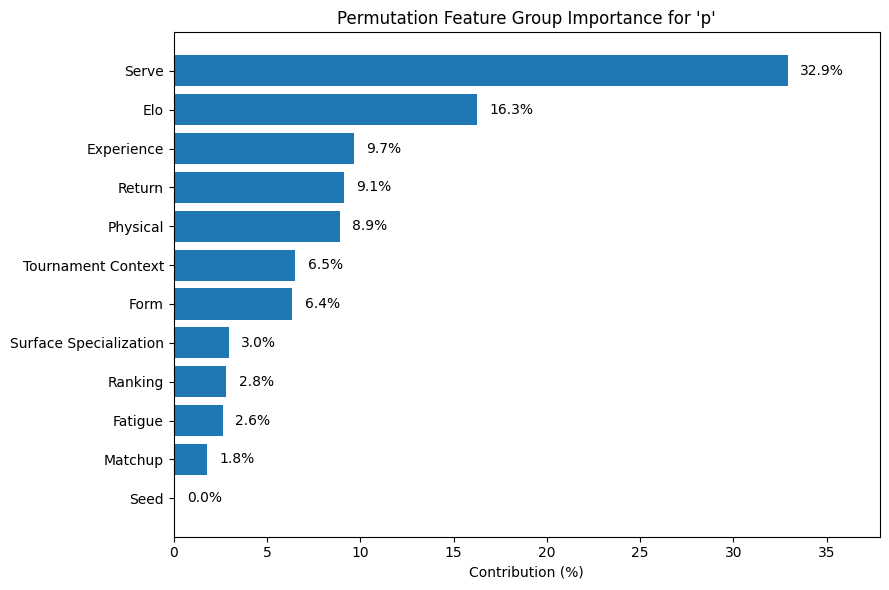

In [122]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

# Create the bars
bars = plt.barh(group_dfA["Feature Group"], group_dfA["Percentage"])

# Add labels
# We use a small offset relative to the max value for dynamic spacing
max_val = group_dfA["Percentage"].max()
offset = max_val * 0.02  # 2% of the max value as padding

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + offset,              # x-position (bar edge + offset)
        bar.get_y() + bar.get_height() / 2, # y-position (center of bar)
        f'{width:.1f}%',            # text label (formatted to 1 decimal)
        va='center',                # vertical alignment
        fontsize=10
    )

plt.xlabel("Contribution (%)")
plt.title("Permutation Feature Group Importance for 'p'")

# Adjust x-limit slightly to ensure labels don't get cut off
plt.xlim(0, max_val * 1.15) 

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


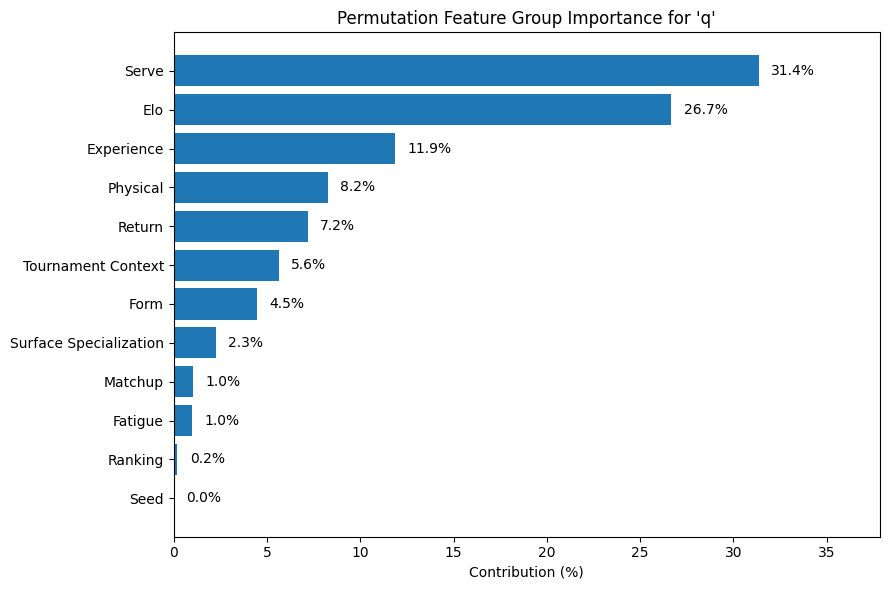

In [123]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

# Create the bars
bars = plt.barh(group_dfB["Feature Group"], group_dfB["Percentage"])

# Add labels
# We use a small offset relative to the max value for dynamic spacing
max_val = group_dfA["Percentage"].max()
offset = max_val * 0.02  # 2% of the max value as padding

for bar in bars:
    width = bar.get_width()
    plt.text(
        width + offset,              # x-position (bar edge + offset)
        bar.get_y() + bar.get_height() / 2, # y-position (center of bar)
        f'{width:.1f}%',            # text label (formatted to 1 decimal)
        va='center',                # vertical alignment
        fontsize=10
    )

plt.xlabel("Contribution (%)")
plt.title("Permutation Feature Group Importance for 'q'")

# Adjust x-limit slightly to ensure labels don't get cut off
plt.xlim(0, max_val * 1.15) 

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()
